# AB_vieillissement_normalisation — normalisation, pondération et score unique (EF 3.1)

## Objet

Ce notebook reprend les résultats d'ACV de la chaîne hydrogène (usage, fabrication, vieillissement) et les exprime :

1. **caractérisés** : 16 indicateurs, chacun dans son unité ;
2. **normalisés** : divisés par l'impact annuel moyen d'une personne dans le monde (résultat en *personne-équivalent*) ;
3. **pondérés** : multipliés par le poids de chaque catégorie, puis additionnés en un **score unique** (en points, Pt ; 1 Pt = impact annuel moyen d'une personne).

$$N_k=\frac{IC_k}{NF_k},\qquad P_k=N_k\times WF_k,\qquad \text{Score unique}=\sum_k P_k .$$

Facteurs : méthode EF 3.1, tableau 1 du document *ACV d'un dispositif IME en PLA* (d'après Sala et al., 2018, et Andreasi Bassi et al., 2023 ; population mondiale 2019 : 6 895 889 018 personnes).

## Points de méthode à garder en tête

- **Catégories disponibles.** La fabrication (stacks, réservoir) est évaluée sur les **16 catégories** EF. Les inventaires d'usage (électricité, eau, compression) ne couvrent que **12 catégories** : il leur manque la toxicité humaine non cancérigène, les radiations ionisantes, l'usage des terres et la formation photochimique d'ozone (19,6 % des poids).
  - Pour **comparer usage et fabrication** (score par km), on utilise les **12 catégories communes** : sinon les radiations ionisantes et l'usage des terres seraient comptés pour la fabrication mais pas pour l'électricité, ce qui biaiserait la comparaison. Ce score porte sur 80,4 % des poids.
  - Pour la **fabrication d'une unité**, le score unique est **complet** (16 catégories).
  - En sensibilité : poids renormalisés à 100 %, poids égaux, et fabrication évaluée sur 16 catégories.
- **Sous-catégories.** Écotoxicité et toxicité humaine (inorganique, organique) sont des sous-catégories de leur total : seules les valeurs totales entrent dans le score unique, pour ne pas compter deux fois.
- **Nature de la pondération.** La normalisation et la pondération ne sont pas requises par l'ISO 14044 : elles aident à lire les résultats mais reposent sur des choix de valeur (poids du JRC). Les résultats caractérisés restent la référence ; le score unique sert à comparer et à hiérarchiser.
- **Unité fonctionnelle** : 1 km parcouru, en moyenne sur la vie du véhicule (15 ans), comme dans `AB_vieillissement_fabrication`.


> **Statut dans l'étude.** L'étude retient trois cas de vieillissement : **optimiste** et **central** = modèle linéaire (objectifs et statut du DOE) ; **pessimiste** = modèle par mécanismes. Les résultats de l'étude sont calculés dans `AB_vieillissement_trois_cas`.
>
> Ce notebook calcule le modèle par mécanismes. Seul son scénario « Pessimiste » correspond à un cas de l'étude. Pour la pile, les scénarios « Optimiste » (cellule B) et « Moyen » restent des analyses de l'annexe S8. Pour l'électrolyseur, les jeux « Optimiste » et « Moyen » ne sont plus utilisés : ils mêlaient l'activité de l'anode (plateau 10,4/93, temps 1,0 kh) et sa capacité (plateau 0,49, temps 1,1 kh), qui sont deux grandeurs différentes.

## 0. Données, modèles et fabrication

Cellules reprises de `AB_vieillissement_fabrication` (modèles PEMFC et PEMWE, inventaires d'usage, fabrication, réservoir, trajectoire sur la vie du véhicule).

In [1]:
from io import BytesIO
from pathlib import Path
import base64,zlib,warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq,minimize_scalar
from scipy.stats import spearmanr

plt.rcParams.update({"figure.dpi":120,"font.size":10.5,"axes.grid":True,"grid.alpha":.25,
 "axes.spines.top":False,"axes.spines.right":False})
OUT=Path("resultats_sensibilite_these");OUT.mkdir(exist_ok=True)
trapz=(getattr(np,"trapezoid",None) or np.trapz)
def unpack(s):return np.frombuffer(zlib.decompress(base64.b64decode(s)),dtype=np.float64).copy()
t_s=unpack("...");I_exp=unpack("eNrtW0trnOcVnlATEmJM0qZppk2bWIllJ5ZixWNb8kWab2Y0kiWNrMvo4onkRIqp4jYutS0otCv/AC8KhYK6yipQyE5Q6K5QKAjUHzDrwIB3BkEg4EUVn+d5hnNmxhrdWrfNtzl87/dez3vu53ypVBtPMpUYnElWnjzTBjvRfr+U/HPz2yef/Gnt2+cE3o/ivZo1uCHYaqkn89ZGMP4q5r9q70enbN3auM2bLgAOY1+jWG8Q48+i/Weah9DaP0gyT543rT01gfFT1r5+Df160H4G876aEDM2/qusO2e1Yu1bNzDPRwZXP8J8eM/gHGs87zuY9wX0K6K9gHMPov85wOP4fiTsYyPbCu+t8N9ue6v59gpt36SbAs6R0f3Y+d4AfJxtfs7G/bXab2y3+XpEF3ZfReA7j/0kaB/E/Qxpv+xn+z2Lfb4l+rB+D1vue3dw5/s86PtpF4927gt2/lIR+BwCXsifoN808VcUvm38qOje81svxo3ivQ/38i7eXxe+bfzXWYOdCaH1ex/z/hD9H2XZ3+O3uud7aN6vekD3Xt3jPjYOaNxO81R32HcVdAJ+ylzFfYzaffxtEnpmGvJzGt8BKzOQo3P4XkH/D0Fv45IbvGeD34j/jD7Jx8OS8/ZeBpz1eq1Eufsuvr8seUT+3h/eqw1y1+a/CDwdx34KgjauH+cFHtMjgOC/1KjXk2t4r1Cfz6PfHOaZBX4ncb5rGAe81qgPBwDfw/7Ip53o3wu8ke/fb9Cb5D8vTx4dMH1uZL3+vgh4Evt+Cfv7sc5l7XW94/X8aeB/wr53/RJ4mQc9Aq8p6oO6XrD2upwi/dj4IclNd5/b8s/ok/oxj/HnATuDnKV8uyL5yvsw2A2YRv/ndQ/N8f+swo1dj7P768Y99uHcHbiHHrS/HejzFPB0XvrD3o9Jrnj9nsE8lwELstdsvmgX5DFv0fN1GnyeauQbbxe9g3W+B7h1YHLeluvHfpJgnw1iH3X7m3LdvZd4jkHQMe2lXEL5ZufmfFca7D77nlc/Z49lsh5uz08/hHxj6/eKT+wd66Zg96UuB77q0D2TL7z9lkE77dQuvL+Kd97/CfGZvZMOqJ/on5ySv+Tt3EH5M5S/1Ff2fRbfqQ8hx78oY17I8aPXpTdtnmnJd8p/u6+yzVctS5/YOhOAvbo/yhOex5/rMuaZwjwzgrbOrPQs9QvtAWs/p/uwcaSPMbSPY55xr59Witqv9eP53sP3c4mzC2tjwMMV9SMk35HPo77anxwaEN/bOahvF3C/Czj3ddDtjO7R9j0BWMJ33NM6/cgRnPNa0CeQM8mU93O3aG/NYjz02WoZ7WW0w/+vzXh6XKW/zDjAUMJzUn4a/rrw/pr4JfpHT/eTdqsHgp8p+ZCT/UI+px/Q3j7qkPqD98l17F7AJ2nKeciFdfo/PQ3xkuZ+brVN+3FA/ifjAox/2HxF0QHjCdbvFNoTyVsn35vsz/PDqOQ25QDtpTje+1vc/0n50fZ+PugZ6t3vh3UuyZ7het6OKnq5tQJ9tjYg+8rv70jSrj9o/V8OcqND+phxLLvvXMI4h9d3xWCn9SmuQ73h/YtW/tTr0juUc4x/Mb7B89IeNjzlpE9pT0S70J+3S3qb+t76FQI9p4PdvNXCvryEeQZ137TPrL1fkHqFdnqMI5BuyN9eP0W/o0t6lXZapBPG3RxfZ/qFJ9Kzt7tayyGvJ2k3dDT4pwfj71yW/WXznsQ6zyWt/M39Pjbv28EvHZB94/hiJS8/lf41+cHHPfMh7gl7YNv+YhzI+l8Iep528SW0FyV3bb4Qt6vV7W7ajaQj2uXEp61/Qffo5e6A6IR+H/fj6eWM5Czpn3FFa09k/zCuZvP0Jj4ucFp+LOmQdMR7oT9Cu4r2FCHx4uVEOvBt63iw7atPdjj5hnKO/gDjM97+o12IfEJtStDFH9KIC6WmlX9gPuAJfBDjNcPeT2feYNu/iPgw+EYLPqxmD5pfdsp/tHroTxC/Nk9O9EF6cXpwW5/td/+GtzofUX+Q3zxfU+90KU5G/XW4+OoQvXGfLm6neFgW+6EczolfDZKvuqU/fHzo613G+6I/TXk/FPik4O2xUk7yhnaq9ad/9UqL/FNrPD11f2nwUykvvHk7Ni/+pp4nXprHHTb2R2+1nLeTalGPDcuupt1A+evzA2828LXtOxv8vB7F07yefNj2eZwdSX1WyzfEbSmHrF8S7PCLwV/qk79q87/YYG/sTY6c9PmrJvGHp/PhJS/fFZ+gHr8Y4s79IZ51JIn2YHv7finkjQohzpM0+BvN5flG2/zy9P0gH3C/KLp0ecRM3Z/y9in9Bq5T9fm09IjiUi5+naZfRj2bachzEM/Uu95uQjw5M4b8/U3MNy4/hXRLu4Ryvbm9zXjnj+T3017mPXg51Rvs7C6fL9is+6/kQ08nD7Muj7g2FvK21xS3snmyPh61dqGBn1rJ88OxjzeCXZaV/CIdubxYeijIg5z27/nhYbY5HRVk57A//WPmXRmH9HSSbshfNz9PMfH1GsO6F4NZ0UG8T3//I0FeHG/IE/l1M8pvsR7E23mjQa8WQv6ju0E/xHWarzeiPLXtdyz41cca4hupZ+R51vazr3OkaR8NhXqNgvjI++kxT1v9r8fDf5pedltHtLf1+xXvtta6H+zjdy/uyMffPYdBH5eD/C4JUg67uIvisccb/NN2+dLHIcdkbzDOspPe+u453Mfugfki5hHHQxzscciHMZ+JPFSGdk5fqMcYkJ9uciHx+bwm8fL/Vfn7/0VPuPfVCvLKM/L/qCfs+zzigRXQB/PayJeulJQHM3hF4ynPXL3Bth/FelxPr1+Fe6EfRDpmnUFJ9O/sRvrLK1nFqb18ZP6jQ3aztZ8P9T4jIQ6MfMoD1gFMqU7b5b9rk8oX+7rW+VAPMIt5ZhSvNTxPBz+LdWLM78+0zKs1zytdQH/qedQr/OAO1rtr4/9xz77/fhXn/BXm/Ux1gt4fYD57yb7/9rbBv/7a4MXbwBvqsr9Ysvc/LAMvy7be55/YPF/ewnyfYp2P5Sc7f+j5z9D/Ds5zy9r/eAfwLvB018Z9s4S8fCXEo1It6k+ivnyUpVwN8ZuGfK2nW8Zl+kOdcyL/02ZZtHke3xN80q/8OzvPX34DfN7UeJ9HGfL5tAegq6GfY50l2RGkb7u/SV+XUFpQPb2Nx7jKguQD41PMfzIvRf1i75Oqn7D2yVAPMxrqKSeUn2G9ns8nx3j4T0BHwEf5F6q7sPGLnv/XRxTP93xIPQq9uF7Pg7j6n8qk6jVY9+LOt7WMcyzLfqZe9fVWH6P9hupsWF/r7mMdeZXSlOp8iB/7DvnTOSc5xfgF9Tjj8Kw3NYj1Vxckt1y90/a8tt6s8GPt4z5vWGI95nXQG/h69Ya9317Geer/Zdg5y/6/lgTybHNR+T6XJ1xdEb/b+y3wAdo7P8X6M57O0+Cn0hIg5U1FctTuFfW461d93k7/iwxJrxjfjAV6KUseG35YRzSPfS8FuQm8rQNvm3Xo8PQ58LkO+fflsu7F5Oic6MLVAddYHzTh64YyJekrO8e86pN57waBt80b6L/o/6vZ5itbdwH15GXxicE51TFRv5Fv7H1a/58wf+XrgrayjJca3mBvHP1E8sz2RXzM6R6Y92G+mvzn6mXWx0Od1DHV4dj+boIOoLf+fsfe/3wP9Ab6qXyofImvG+0P9dy0C3LBLqGcmVS8lnWBVsYKut08H+phnwt+V5f+27D2q+H/rM4Gfy3G6b0ddEZ1uc3rkKoH/l9L07of5ZdD/nw9n7j8lepeB0MdUDHkK7pVX+zjWYMhLpoNdSk9oc7qlZb19c3P99OQf8qHuou84sPezuwO/9NcQvuw6l59vDelOD/rbVz+MzUS/ocrqB6KcVqTo5PKV9i4s4GPekI9FvMt5+RXst6McaPm9tXB/S/FOLevP6Wf2vr/kMP6n2u//HFY/5+1x49Fn58mHylPnPN5U8X9hyTXY15wv/e+Vzni/duuUK9X/y/V+007xwn+Xf8DNv//D3U0aerbBejHRW+HZRZDvf0L4X+K6q7x7v4jfDCpemTa597efS3x/BnyNfdLifsvZ7Mv1KUeD375Vpt1eYOqu6Y/y/oa1tHs9tyRP1y9fC1RHYmre64VGv6PbreugHX4jMszrxrl/u708YnE/wfM+pK3Guqy/W4+CPmA06rniuPifnxevRDqRWMcubpj/cB+43X/Ap+LajI=");U_exp=unpack("eNp1W3+IVmUWVhSZQZEZXMTBYXAYGRwcZMSQQomJIlaScDGkMEIxZNv0+973U0JJQlmRlSIMJZpNoihko4jERRQljJFImhXFRZIkDBdpSEJRJElk657zvM8859r3z8u997vvfe95z4/nPOfcSZN++61qDm/8/dffGP7P2G+/683h309PutEY/ufIb7/J2a7/nOx43Md2P/+kjxezne9s+fWWzTPUGl5S/Vo2/598vJft+td+/5vZ/+fn/8yxun4tlbGavyvbPFt9fMaf/4jP87Lf39bSdT3m5+f5ca+Pd33+iz7O9nmX8/7qvg6+h/2PY/W/vyS7/hDH6vrSZOt6PJV1VNefz0Vess5duYzVfWvDutu5jur8w37c7evpD+tu8/GKz/uBy3WNH99Mdn2dr3O/68G+hu+zj0eb9pxB15fL/r91fr3H77/QsPFW0/fL7xtr2P8/b9r1b/y9/uXvOcv1ZTrljWOR9yLKoTo+6/e/7vMN+/vdcfm/4uu66us54+t9we9b7ePf/b63fX8+8nGHn2+4vPb6c3b6cZevc4qvp4ejyP8X//+XPm73587148O+3iddT467fV50e7y72eY55/Ls9nGl78eYHx90Oc/B+/t7P+L7Mgt67vuwn/tp++zPO9Ms+lAdv+T/m+/372kW/RM73hLktYvnYbe4DjuX80tbZYTcbN99nOn6/hD1w97Pzw/6fcfoB6Bfph/+/wGer+6b0Sr+zPQffiCr/3suqVy2N4ocTX+wP/Cjbl+f+760uX9YHuR/MtjTzFT22fTBz1/kfdhn2x//34CvZ7o/t8P3dU+j2EF1/BXtsbrvY1/3Dn/ONO6z+Stf5wx/3nafZ42f7/bnJV/fan//Xp/nK5drov8xO/HzHbn4Y/FL3+J+H9/z8/9w+azMNb9YPb+P/qI6/2Iudm/v5+NZn/ezVOJINf+2oD/RL/VR7xBPcB7+rXruJszjx5/6up/w93if+ws/L37vkNvPEb//NvWzur6R/q8aN9C/mB1Rvjafv+d5X8d/fR1z/L5en6eP/hTxozq/zOU5P8TF237/S/SL2Bfx78sCPpgV7HB5sP8FvG54xNdziv64uv4U5JNKHDR/mYt9I05W///O73+L+AX/M3lwHbYfPs+9RtEXPE/0ZVvd75ifp3+ydXC/1B5aRY7V8Ws+37e5yBt6Cn9odkx9s33NNfwi+7GQ8oVcDJ8E3NYd7rvl676QVT+3+PMW+/FV17O3gHt8X+4Ad7q/G3a939csfsXsgLjU9N//txN+0s/Pcj8zzvhldtYsuA5xytbXUjzVyf1GfKjuux9wZFfQx+n0L4gb5pez+p17Wf3Dh/wfjoE34j7J+oY5H/Qk6pXs008+778DLp6Tiz+tzr/q8hkCDtxUcBXWVf3vXeI14CTonej9Pl6v1jNC3GlxjiP+X80/SjsVf/6Rz7cH/tPHg37fq8QT1fkDWf3vG8F+5gD3+7rOh/ylk/Yh9t9HXAe7kHgzmote4LzF/4BLJoV9nB30aQ3fw/Q0l7wE+4Y4Aj8k9tbu6/jEzx9h/mTrgnz8+LJf/8KPBxkf4UewT6L/v+ZiJ+IHRoFfU8G1pie+nhOpxJnq/LMhrv3o4zq+P/wv4pjJMfj9qdhH5kvAjxKX51IvJO5M2A/J86YRbwre7aE/FP/7Yt3OqnVd8vPv+DiEvMOv73I5neK+GC7jvpn8Gd+Bn6vjFbn8D3kx5Gh+NJWxWtf3vh8f+nNGiLcM/yfVt5MpxMGkeol88jB5AeAEjILDO+hXJe731O1P7GcCPrL3ob2Ln9nKuIR8DfYf82XgEYkPHcGOb+aCY6EX1f9WEVcibiNvh58yvEd/A73EOiSPnx/ym4UhP7mWS34j+elMygf/Q/yzecmTiN/az/hQ/f/prP6xi/hW/N+nLxd5Sb47zP2J/rD636N1XA77F/+9MODCwYC7kf8vov1DD4EPY7yQ/HxaXZ8EFw3xeZKHPppVj9tamrfODLzCJ7nkKRhx3fx3yF/mUz6I76KXbYwjwLExP4nygp5DDvBD8F8iFzz3cT4X8Q14W+Lx8oBXejkKfprACwqO2Ej+Bbgg4g3gdNgb/JrwP1uyyquz9eD32hLmvxF4zO0Bz575g7iwiPKFHCROzAn5zgL6K/E/M1tqZzcpB+B/5HHivw/5+EIqeM/yyVzDiViXrP8+/RnsH7yv6YnHg2HEAecBZpAPAL8jOHOU/kiev5vyxX3GTwX+55Vw/n+55uex7gfm/ReYBxlf42MO8fmvATduJT8heDn59dMhrh2gXwHOFTwwj/YIf4M4AT1GnAB/Bn0DTwj/gbgq8airpfzj3BBPZ2zS/OBg1vzj3ax5zS+M1w+Mg1Ppb5BXw39hFB5iP/NbwS/fkm83eaVSZwAfJDwErt8PvNDXSesF67LyGAOMA+JH2rkfEtf6yQuKnfQHnn+yjz+QlxH9Qpw9H3Ddwz5e8fx1lY+nnE9Y6vzckWbh+bAey2spd+iZxOn2P8BPswM/83FW3HInFXu3+IY8nf5E/NmtgFt+DPY+k/5O8NZ85l2WbwS5dQPXuJzmwf+QlzS9bhT9tDyD9iH1jUPBrw+0FDedpl8R3qWL68R7SF49N+RrP/t+nCDOBN4z+bieL+P7wq8j7gm/9wb5AsF9swNuHmjpPkxqKT6FX5uRSx5o+BR5xcbiD5C/QJ7CnyNvfrilOO025SN83VDAZ9foxxDvxb6/S6oHB4hr5X3XB15+B/0kcEDEIeIvD5OXEdx2n34Q+FT0YHHAsWNZ4x74xA31Oofow4Gw/meC/7jE/AB2FPGMrGN5q5bnIn7AD0veAT/3dC75u8zfTtwndZKuIK+viB8l/p0P9bOxrPXeecGPdhHfSxy/HniilawTSN33QPBPHS0dY/xd9Ae8zOWQJyBvXMY8F/EG/Kjo0x7uM/ya8FazQ7xZXLdf1NMl/veyriZ10rmhXryY82Pdwv8hbx7CcdI6wVtBL3dnrXNsyDX9Fr58aqvUCSTe3wv10avBX3wReMAJPKvYKex/RdZ87wnyQ4ZvAw45EnDbnax4aH5L+cDOoIe3g18Zod0i3zTci7qXx81FjPOoy1nc9Di/8W/Kl3wQeNM9We3iZi71ZZFn5Odhp89mjRdDzJOBZyWe93EfJX9rp35Jv8E28nbg3yQvPsK8SuJTR/CvKwL/+2vIi6bV62ywT9wvcWQt4xb0OvI8wuvPC3npcEvrBFGea6h3wgt21+OzHP8S8rkXiLvMj4Z64A3XmxWOD9/3usck1pcNNxAXATfivPkjx0s7HE8eCv0PF9k3YHlbo9RZpN5yxa9P8XmHGrrOgXrdWeo4+/w5g8C7/v+7qDOzzoM6tdTDVxEPC9+5N+C91wKP1B3qeW08hj8CTgS+QH+R+vtU5Gh4CfWmzSrPV1j3h9wsrrhctqAPw+dZ4ucv+PmRhu7TCta3pA52oVHkZ/e5XFKj3Gc40v+/gftlx359uT9/iseD1c2Sh9j86C9hnc5wSrPU+e29ub9YP/oLLL4GeXTz/dEfIXnPzJbyAT2hnjUBDwtvNyvwpnPJ66OOIfzXOuIK8OHSX4B+qL6kdrK6qfbzfKO8D/RW7PQW9oV9VHJ9g9+3yY/7Qp8V7KCDfRWiN3dxP89jfYa/2c+DfNPk1Sy8Dkbolz23bv9Yl/nNjVqfWUveRupybwYc3xn4sBmhH2d6S/O2XeyXM/8c6o2RR28Ldf6+er0GeQ7WKbz47VC3SvTPZv+sM5tdbdZ+ONjF7Ib2nd1tFH8o/V1vu7wPNkt9G31dsj9LQ1/RuM873ih+BvYpdoe+o3P+/0thHZd8/juNol/wF6jTi3+fwr4y+EOpFw5m5bkmEY8L/m5nXVP4qPHAJ7wX8ryjucZDSF6+MD6npXWXnaGfDP2t631/R2m3sGvT32B3440Sn2HP0rdwkvHW/Dft3NYV+rGOhvj7YVP9y5Fm8bOyrnPsj0BfmcSj5fADoW+wO8wzwc6lr+sy+4LRnyb611Xv1wAukP7iqan0bSBeAQ9ov0ZD/ff1pHXdr4nrjYdz+zxNfhB9KNaXG/KaUyHvOBbqt1MDrlsU+oF6Qt3xKfopyYOW0F8BX0g9cCz0aZ3N2h/QHerXsI/HcuEfYQ82kkeV+jj4gqlcr+RpB0MfwU+oV7MejD4x+GHUuew9ktadr9fxtfh9nF+ctE7+fVLce6Wh/ZXAMe83Sx+l6RdxucU12HlS3DXQ1P7jE+wPljrKyz4+lYrdAA+Z30yFfxD5rwl2fIu4Gjhd+N5p7JeAPki9qr+l/GMv+Rmp58T6el+oJw9ylPorcOZ41n7sY4EvH0kl7pg8vT/oqPcjb0vFHsEnSv8P6hhTsvY3f5lKvg7+BTyF9B+8Db0DTiVfbfg/KQ8Cfmmc9QCM0H/poxgIdvUccaHUgdBHcTno9wD7vyW/Od4sdih2dDL0ZxzLpQ8DeSH8GOIj6gmWJ9MfSv/mUIhrPezreqD9TW6V65Cr4CD0e8yivUu94HbSOhv6R44l5bVRB7oa+uDwHot9nq1J+baOrP0pX6bi74E7wRubf3R5Nfz5C31cCz8RcNxa8DRJvxe4mMr3HKJPqAuPup0/2dR+51HiaKwX330IjlzJUd7vZlI/uD3wq+upj+C7RH9/wPcXHJHHgv+X50HuY8Ge9rK/GnUr6JPhiaTfERxKxY+hXof+BvleZ2rgUxdkfe89qfhXjMZXB35kFfVa/MIG9rFBD9E/JfpznH1NhmtSrY4s/Qvgk1NW/VhBPZN88Tv2t4HPk36E/sBzLq3X7+R7igl9/GZX8MMN7cNCf/y1wB+fDfrSGerJu3Opr6JeJHW8c/yOKfY1x75q09ukdY8d7A+QvoOegKfmB/4RfVRLwvdLvYG36wj1/yn0/1IP+STwRuuz4sTJob/yAPdVvssaCX2l79DPmd0wz5B6+KtZ4+SS4I9f4n5IXvox543fFcW+Venz6a7344BnRb0J9bj4vY7wMIMBV6Bf6kRWO28Ped7tgNNzqPc+xLiMvgxZX6nPpIIf5Huf8dAPgfrujazXdwT+vLdex5W+G/SJ9aO+lMp3T+Dzbf8b+r0O8q1NzVrfsNTvloW+nzPxu0Xgr6Q4Et8J3duseeDVhvKK4HHBA3+OugOP5T3GyPcY/uH74Rj4W74HmhH6Fe5s1rrHCuJg5LHSv7+qof0QwzwGD4n8P+ZrqDMIruhqaf3scNa65WziYuy/8Pingx10EtfgPYRPubG5yEPyk53Mb8Hr4Ls84X3Ohv6l7sBXdgd7upe13+F4wAVTcugjDrxwV6PwSPberE/hWNa5van9FiPN8h2i8FKH2Pci/eRH+f2HxMX2+vezkp9MC31cu7PmeSfdHp9J2n/0aMizu0N99H6u8cPwl4bTwveKt0IddFbov+xgXUr6Lz4LdeuN7Kc3/d6s/acdoW/3aOi/H+T3g7ZO34+9zZKngReRuHc4fCc1kmu8gvRJDAb9+5TfeUvdq7/+fbXMuyD4tx9CX8cg+5hQpxPe905Wv9lbrweiD036bifsr/QftQU+GfXT1+vfCSg/0ap9jxL7/4TvuUrcbH4+Ke82SB4VdbT/AzkK77Y=")
dt=np.diff(t_s,append=t_s[-1]+np.median(np.diff(t_s)));active=I_exp>0;P_dem=I_exp*U_exp
N_MC=1000;SCENARIOS=["Optimiste","Moyen","Pessimiste"]
COL={"Optimiste":"#2F6B5F","Moyen":"#D89B2B","Pessimiste":"#A64B4B"}
def pct(a,b):return 100*(np.asarray(a)/np.asarray(b)-1)
def percentiles(df,cols,name):
 return pd.DataFrame([{"Analyse":name,"Sortie":c,"P5":np.nanpercentile(df[c],5),"Médiane":np.nanpercentile(df[c],50),"P95":np.nanpercentile(df[c],95)} for c in cols])
print(f"WLTP : {len(t_s)} points ; durée {dt.sum():.1f} s")


WLTP : 2033 points ; durée 2032.9 s


In [2]:
OUT=Path("resultats_normalisation");OUT.mkdir(exist_ok=True)

In [3]:
R=8.314462618;F=96485.33212;M_H2=2.01588e-3
FC_T=343.15;FC_N=330;FC_A=297.   # surface active estimée par Pielecha et Pielecha (2025) : Mirai I (237 cm²) × 1,12 (puissance) × 1,12 (nombre de cellules)

# ---------------------------------------------------------------- cinétique (littérature)
# Oxydation de l'hydrogène très rapide : perte anodique négligée (Durst et al., 2014).
# Réduction de l'oxygène : coefficient de transfert alpha_c = 1 (Gerling et al., 2022 ; Vetter et Schumacher, 2019).
FC_AC=1.0
FC_E=1.229-0.85e-3*(FC_T-298.15)          # tension réversible à T (V/cellule)

# ---------------------------------------------------------------- polarisation (identifiée dans AB_vieillissement_PEMFC)
# Le courant de pertes d'hydrogène n'entre PAS dans l'équation de tension : il n'est compté que dans le bilan d'hydrogène.
FC_I0C=1.5249284032896347e-06             # courant d'échange cathodique effectif (A/cm²)
FC_R0=0.046227991773348694                 # résistance surfacique apparente (ohm.cm²)
FC_BC=0.026458911532429897;FC_ILIM=2.30179979134735

# ---------------------------------------------------------------- courant équivalent de pertes d'hydrogène
# Réservoir 5,6 kg : 56,0 % -> 52,5 % pendant le WLTP, soit 0,196 kg ; la loi de Faraday n'en explique que 192,4 g.
# L'écart (perméation, purges, incertitude de la jauge) est exprimé comme un courant équivalent de pertes.
# Ce n'est pas un crossover mesuré.
FC_H2EXP0=.196
FC_TACT=float(np.sum(dt[active]));FC_QEXP=float(np.sum(I_exp*dt))
FC_CROSS0=(2*F*FC_H2EXP0/(FC_N*M_H2)-FC_QEXP)/(FC_A*FC_TACT)

# ---------------------------------------------------------------- vieillissement (littérature)
# Colombo et al., J. Power Sources 553 (2023) 232246 : 1000 h de cycle automobile ID-FAST.
#   S_min : ECSA normalisée mesurée à 1000 h ; x_ratio : facteur sur le crossover en 1000 h (appliqué au courant de pertes) ;
#   dV_low / dV_high : pertes de tension à 0,08 et 1,8 A/cm² après 1000 h.
COLOMBO={"B":{"S_min":.65,"x_ratio":1.4,"dV_low":7e-3,"dV_high":27e-3},
         "C":{"S_min":.67,"x_ratio":2.6,"dV_low":22e-3,"dV_high":45e-3}}
J_LOW,J_HIGH,T_TEST=0.08,1.8,1000.
# V16 : décomposition de Colombo et al. (2023) : HFR constante (pas de hausse ohmique), perte cinétique liée à la surface
# de platine, reste de la perte à fort courant = transport de l'oxygène, représenté par une résistance linéaire (Jouin et al.).
#   r = [perte mesurée à 1,8 A/cm² - (RT/alpha F) ln(1/S_1000)] / 1,8 A/cm² / 1000 h
def r_app(c):  # hausse de résistance apparente (ohm.cm²/h)
    dv_cin=R*FC_T/(FC_AC*F)*np.log(1./c["S_min"])
    return (c["dV_high"]-dv_cin)/J_HIGH/T_TEST
def r_app_diff(c):  # ancienne méthode (sensibilité) : différence entre fort et faible courant
    return (c["dV_high"]-c["dV_low"])/(J_HIGH-J_LOW)/T_TEST
# Perte d'ECSA : loi de Verducci et al., éq. (8), sous forme temporelle : dS/dt = -k S^2 exp(omega S), omega = 3,6 (3 à 4).
# k est calé pour chaque cellule sur l'ECSA mesurée à 1000 h (B : 0,65 ; C : 0,67).
FC_OMEGA=3.6;FC_OMEGA_BOUNDS=(3.0,4.0)
_FCTAB={}
def _fc_table(w):
 key=round(float(w),6)
 if key not in _FCTAB:
  S=np.linspace(1.0,0.02,6000);f=np.exp(-w*S)/S**2
  g=np.concatenate([[0.],np.cumsum(.5*(f[1:]+f[:-1])*(S[:-1]-S[1:]))])   # g(S)=∫_S^1 exp(-w s)/s² ds
  _FCTAB[key]=(S,g)
 return _FCTAB[key]
def fc_kS(p):
 S,g=_fc_table(p["omega"]);return float(np.interp(p["S1000"],S[::-1],g[::-1]))/T_TEST
def fc_from_ccm(c):
    return {"S1000":c["S_min"],"omega":FC_OMEGA,"k_R":r_app(c)/FC_R0,"k_mem":np.log(c["x_ratio"])/T_TEST,"eol_frac":.10}
FC_SCEN={"Optimiste":fc_from_ccm(COLOMBO["B"]),"Pessimiste":fc_from_ccm(COLOMBO["C"])}
FC_SCEN["Moyen"]={k:(FC_SCEN["Optimiste"][k]+FC_SCEN["Pessimiste"][k])/2 for k in FC_SCEN["Optimiste"]}
FC_SCEN={k:FC_SCEN[k] for k in ["Optimiste","Moyen","Pessimiste"]}
FC_CENTRAL=FC_SCEN["Moyen"]
FC_BOUNDS={"omega":FC_OMEGA_BOUNDS,
           "k_R":(FC_SCEN["Optimiste"]["k_R"],FC_SCEN["Pessimiste"]["k_R"]),
           "k_mem":(FC_SCEN["Optimiste"]["k_mem"],FC_SCEN["Pessimiste"]["k_mem"]),
           "S1000":(COLOMBO["B"]["S_min"],COLOMBO["C"]["S_min"])}

def fc_fa(t,p):
 if p["S1000"]>=1:return np.ones_like(np.asarray(t,float))
 S,g=_fc_table(p["omega"]);return np.interp(fc_kS(p)*np.asarray(t,float),g,S)
def fc_R(t,p):return FC_R0*(1+p["k_R"]*np.asarray(t))
# Écart mesuré (FC_CROSS0, source inconnue) : constant. Crossover : 2 mA/cm² au départ (spécification DOE, membrane neuve),
# croissance de Colombo et al. ; seule sa hausse s'ajoute. Fin de vie : -10 % de tension (DOE) ; le seuil de 15 mA/cm² n'est qu'un cas de sensibilité.
FC_X0=2e-3
FC_FORME_X="lineaire"   # V13 : loi centrale ; "exponentielle" (Jouin) et "constant" (Toyota) en comparaison
def fc_crossover(t,p,forme=None):   # crossover seul (A/cm²), 2 mA/cm² au départ (DOE), facteur de Colombo en 1 000 h
 forme=FC_FORME_X if forme is None else forme;t=np.asarray(t,float)
 if forme=="exponentielle":return FC_X0*np.exp(p["k_mem"]*t)
 if forme=="lineaire":return FC_X0*(1.+(np.exp(p["k_mem"]*1000.)-1.)*t/1000.)
 if forme=="constant":return FC_X0+0.*t
 raise ValueError(forme)
def fc_cross(t,p):return FC_CROSS0+fc_crossover(t,p)-FC_X0   # écart constant + hausse du crossover
def fc_vcell(I,t,p):
 j=np.maximum(np.asarray(I,float)/FC_A,1e-12);fa=fc_fa(t,p)
 return FC_E-R*FC_T/(FC_AC*F)*np.log(j/(FC_I0C*fa))-j*fc_R(t,p)+FC_BC*np.log(1-j/FC_ILIM)
def fc_U(I,t,p):return FC_N*fc_vcell(I,t,p)
FC_IREF=300.;FC_U0=float(fc_U(FC_IREF,0,FC_CENTRAL));FC_IDOM=.995*FC_ILIM*FC_A
def fc_eol_tension(p,maxh=60000):
 target=(1-p["eol_frac"])*FC_U0;g=lambda t:float(fc_U(FC_IREF,t,p)-target)
 return brentq(g,0,maxh) if g(maxh)<=0 else np.nan
# Critère de membrane (sensibilité seulement) : âge où le crossover atteindrait 15 mA/cm² (seuil d'arrêt des essais du DOE).
FC_XNEW=0.002;FC_XFAIL=0.015;FC_RFAIL=FC_XFAIL/FC_XNEW
def fc_t_membrane(p,ratio=None,forme=None):
 ratio=FC_RFAIL if ratio is None else ratio;forme=FC_FORME_X if forme is None else forme
 if p["k_mem"]<=0 or forme=="constant":return np.inf
 if forme=="exponentielle":return float(np.log(ratio)/p["k_mem"])
 return float((ratio-1.)*1000./(np.exp(p["k_mem"]*1000.)-1.))
def fc_eol(p):
 """V12 : fin de vie = -10 % de tension à 300 A (critère du DOE). Le critère de membrane (crossover à 15 mA/cm²) n'est qu'un cas de sensibilité (fc_t_membrane)."""
 return float(fc_eol_tension(p))
def fc_eol_cause(p):
 return "tension"

# Ancrage point par point : à l'âge zéro, le courant est exactement celui du WLTP mesuré.
Umod0=fc_U(np.maximum(I_exp,.1),0,FC_CENTRAL);anchor=np.ones_like(I_exp);anchor[active]=U_exp[active]/Umod0[active]
def fc_power_peak(t,p):
 q=minimize_scalar(lambda x:-float(x*fc_U(x,t,p)),bounds=(.1,FC_IDOM),method="bounded")
 return float(q.x)
def fc_currents(t,p,niter=40):
 ip=fc_power_peak(t,p);lo=np.zeros_like(I_exp)+1e-9;hi=np.zeros_like(I_exp)+ip
 feasible=(~active)|(P_dem<=anchor*ip*fc_U(ip,t,p)*(1+1e-10))
 for _ in range(niter):
  mid=(lo+hi)/2;low=anchor*mid*fc_U(mid,t,p)<P_dem;lo=np.where(low,mid,lo);hi=np.where(low,hi,mid)
 cur=(lo+hi)/2;cur[~active]=0;cur[~feasible]=np.nan
 return cur,feasible
def fc_h2_model(t,p):
 cur,ok=fc_currents(t,p);total=cur+FC_A*fc_cross(t,p)*active
 return float(np.nansum(FC_N*M_H2*total/(2*F)*dt)),float(np.nanmax(cur)),float(ok.mean())
FC_H2MODEL0=fc_h2_model(0,FC_CENTRAL)[0]
def fc_state(t,p):
 hm,imax,ok=fc_h2_model(t,p)
 return {"fA":float(fc_fa(t,p)),"Rratio":float(fc_R(t,p)/FC_R0),"icross":float(fc_cross(t,p)),
         "U300":float(fc_U(FC_IREF,t,p)),"H2":hm,"Imax":imax,"feasible":ok}
display(pd.DataFrame(FC_SCEN).T.assign(r_app_mOhm_cm2_kh=lambda d:d.k_R*FC_R0*1e6).rename_axis("Scénario"))
print(f"Courant de pertes H2 : i_pertes,0 = {FC_CROSS0:.6f} A/cm² ; H2 initial modèle = {FC_H2MODEL0:.5f} kg/WLTP (mesure : {FC_H2EXP0} kg)")
for n,p in FC_SCEN.items():
 print(f"{n:10s} : -10 % de tension à {fc_eol_tension(p):7.0f} h -> EoL = {fc_eol(p):7.0f} h ({fc_eol_cause(p)}) ; crossover à 15 mA/cm² (sensibilité) à {fc_t_membrane(p):7.0f} h")

,S1000,omega,k_R,k_mem,eol_frac,r_app_mOhm_cm2_kh
Scénario,,,,,,
Optimiste,0.65,3.6,0.000171,0.000336,0.1,7.923103
Moyen,0.66,3.6,0.000285,0.000646,0.1,13.172031
Pessimiste,0.67,3.6,0.000398,0.000956,0.1,18.420959


Courant de pertes H2 : i_pertes,0 = 0.002165 A/cm² ; H2 initial modèle = 0.19600 kg/WLTP (mesure : 0.196 kg)
Optimiste  : -10 % de tension à    5808 h -> EoL =    5808 h (tension) ; crossover à 15 mA/cm² (sensibilité) à   16250 h
Moyen      : -10 % de tension à    3828 h -> EoL =    3828 h (tension) ; crossover à 15 mA/cm² (sensibilité) à    7160 h
Pessimiste : -10 % de tension à    2895 h -> EoL =    2895 h (tension) ; crossover à 15 mA/cm² (sensibilité) à    4062 h


In [4]:
# ---------------------------------------------------------------- état neuf du PEMWE
# Lu dans pemwe_parametres.json, écrit par le notebook AB_vieillissement_PEMWE (exécuter celui-ci d'abord).
# Cinétique : alpha_a issu de la pente de Tafel mesurée (46 mV/déc, Padgett et al. 2025) ; cathode négligée ; E_rev(T).
import json as _json
from pathlib import Path as _Path
_PJ=next((p for p in [_Path("pemwe_parametres.json"),_Path("resultats_PEMWE_temperature_vieillissement")/"pemwe_parametres.json"] if p.exists()),None)
if _PJ is None: raise FileNotFoundError("pemwe_parametres.json introuvable : exécuter d'abord AB_vieillissement_PEMWE et placer le fichier à côté de ce notebook.")
PEMWE_P=_json.load(open(_PJ,encoding="utf-8"))
WE_T=PEMWE_P["T_K"];WE_R0=PEMWE_P["R0"];WE_ETAF0=PEMWE_P["etaF0"]
WE_E0=PEMWE_P["E0"];WE_H20=PEMWE_P["H20"];WE_SEC0=WE_E0/WE_H20;WE_V0=PEMWE_P["Vmean0"]
# Fin de vie (DOE) : +10 % de tension au courant de référence, le courant moyen du profil (j_ref).
WE_VREF0=PEMWE_P["Vref0"]
WE_W0=PEMWE_P["W0"];WE_WJ=PEMWE_P["Wj"];WE_JMEAN=PEMWE_P["j_ref"]
# Conversion activité -> tension : pente de Tafel mesurée par Padgett et al. (2025), identique à celle du modèle neuf.
WE_BTAF=PEMWE_P["b_tafel"];WE_CDEG=WE_BTAF/np.log(10)
print(f"PEMWE (fichier {_PJ}) : R0={1e3*WE_R0:.1f} mOhm.cm2 ; V_ref(0)={WE_VREF0:.4f} V ; SEC0={WE_SEC0:.3f} kWh/kg")

# ---------------------------------------------------------------- constantes issues de la littérature
# Padgett et al., J. Electrochem. Soc. 172 (2025) 054508 — 4000 h à 3 A/cm², 80 °C, 0,4 mgIr/cm² :
#   activité massique (IrO2 amorphe qui cristallise) : plateau 10,4/93, temps 1,0 kh ;
#   capacité (proxy de la surface active seule) : plateau 0,49, temps 1,1 kh ;
#   HFR : 7 µV/h à 3 A/cm² ; couche catalytique (CLR) : 3,4 µV/h à 3 A/cm² (liée à la dissolution d'Ir).
PADGETT={"fA_masse":10.4/93,"k_masse":1/1000.,"fA_capa":.49,"k_capa":1/1100.,"dHFR":7e-6/3.0,"dCLR":3.4e-6/3.0}
# Cas de stress (sensibilité seulement, non représentatifs d'un empilement commercial) :
RAKOUSKY_R=12e-6/2.0   # Rakousky et al. 2016 : 12 µV/h à 2 A/cm², 80 °C (toute la dérive attribuée à R)
PAPA_R=43.5e-6         # Papakonstantinou et al. 2020 : 43,5 µΩ.cm²/h, 60 °C, Ti non revêtu (cas de stress)
# Chandesris et al., Int. J. Hydrogen Energy 40 (2015) 1353 : 50 % d'amincissement à 353 K (80 °C) en 110 100 h (modèle linéaire)
#   et 80 700 h (modèle couplé) ; à 333 K (60 °C) : 590 500 h et 380 500 h (sensibilité).
CHANDESRIS_T50={"lineaire":110100.,"couple":80700.}
CHANDESRIS_T50_60C={"lineaire":590500.,"couple":380500.}
# Points de validation (non utilisés pour caler) : DOE 2022 4,8 µV/h (40 000 h) ; DOE 2026 2,3 µV/h (80 000 h) ;
#   Siracusano et al. (cité par Maoulida et al. 2026) : ~5 µV/h à 1,6 mg/cm², ~15 µV/h à 0,5 mg/cm².
WE_VALID={"DOE 2026 (cible)":2.3,"DOE 2022 (état)":4.8,"Siracusano, 1,6 mg/cm²":5.0,"Siracusano, 0,5 mg/cm²":15.0}

def we_params(fA_min,k_cat,r,t50):
    return {"fA_min":fA_min,"k_cat":k_cat,"k_R":r/WE_R0,"t50_mem":t50,"eol_frac":.10}
_mid=lambda a,b:.5*(a+b)
# V18 : seul le jeu « Pessimiste » est utilisé dans l'étude (cas pessimiste) ; « Optimiste » et « Moyen » sont gardés pour mémoire.
WE_SCEN={"Optimiste":we_params(PADGETT["fA_capa"],PADGETT["k_capa"],PADGETT["dHFR"],CHANDESRIS_T50["lineaire"]),
         "Moyen":we_params(_mid(PADGETT["fA_capa"],PADGETT["fA_masse"]),_mid(PADGETT["k_capa"],PADGETT["k_masse"]),
                           PADGETT["dHFR"]+.5*PADGETT["dCLR"],_mid(CHANDESRIS_T50["couple"],CHANDESRIS_T50["lineaire"])),
         "Pessimiste":we_params(PADGETT["fA_masse"],PADGETT["k_masse"],PADGETT["dHFR"]+PADGETT["dCLR"],CHANDESRIS_T50["couple"])}
WE_CENTRAL=WE_SCEN["Moyen"]

def we_state(t,p):
 t=np.asarray(t,float);fa=p["fA_min"]+(1-p["fA_min"])*np.exp(-p["k_cat"]*t)
 # crossover proportionnel à 1/épaisseur ; épaisseur e/e0 = 1 - 0,5 t/t50 (Chandesris et al., 2015)
 eta=1-(1-WE_ETAF0)/(1-0.5*t/p["t50_mem"])
 dv=p.get('b',WE_BTAF)/np.log(10)*(-np.log(fa));vm=WE_V0+dv+WE_R0*p["k_R"]*t*WE_JMEAN
 en=WE_E0+dv*WE_W0+WE_R0*p["k_R"]*t*WE_WJ;h=WE_H20*eta/WE_ETAF0
 return {"fA":fa,"Rratio":1+p["k_R"]*t,"etaF":eta,"Vmean":vm,"Vref":WE_VREF0+(vm-WE_V0),"Energy":en,"H2":h,"SEC":en/h}
def we_eol(p,maxh=400000):
 # tension au courant de référence j_ref = WE_JMEAN : V_ref(t) = V_ref(0) + ΔV_cin + R0 k_R t j_ref
 g=lambda t:float(we_state(t,p)["Vref"]-(1+p["eol_frac"])*WE_VREF0)
 return brentq(g,0,maxh) if g(maxh)>=0 else np.nan
display(pd.DataFrame({n:{"f_A,min":p["fA_min"],"k_cat (1/h)":p["k_cat"],"dR/dt (mOhm.cm²/kh)":1e6*p["k_R"]*WE_R0,
  "k_R (1/h)":p["k_R"],"t50 membrane (h)":p["t50_mem"],"EoL (h)":we_eol(p)} for n,p in WE_SCEN.items()}).T)
print(f"PEMWE central : EoL={we_eol(WE_CENTRAL):.1f} h ; SEC0={WE_SEC0:.4f} kWh/kg")
print("Taux moyens équivalents (µV/h) = 10 % V_ref / EoL :",{n:round(1e6*.10*WE_VREF0/we_eol(p),2) for n,p in WE_SCEN.items()},"— références :",WE_VALID)

PEMWE (fichier pemwe_parametres.json) : R0=215.5 mOhm.cm2 ; V_ref(0)=1.8600 V ; SEC0=53.676 kWh/kg


,"f_A,min",k_cat (1/h),dR/dt (mOhm.cm²/kh),k_R (1/h),t50 membrane (h),EoL (h)
Optimiste,0.490000,0.000909,2.333333,0.000011,110100.0,61311.455642
Moyen,0.300914,0.000955,2.900000,0.000013,95400.0,46533.275923
Pessimiste,0.111828,0.001000,3.466667,0.000016,80700.0,34175.406934


PEMWE central : EoL=46533.3 h ; SEC0=53.6756 kWh/kg
Taux moyens équivalents (µV/h) = 10 % V_ref / EoL : {'Optimiste': 3.03, 'Moyen': 4.0, 'Pessimiste': 5.44} — références : {'DOE 2026 (cible)': 2.3, 'DOE 2022 (état)': 4.8, 'Siracusano, 1,6 mg/cm²': 5.0, 'Siracusano, 0,5 mg/cm²': 15.0}


In [5]:
IND=["Acidification","Changement climatique","Écotoxicité totale","Écotoxicité inorganique","Écotoxicité organique","Énergie fossile","Eutrophisation eau douce","Eutrophisation marine","Eutrophisation terrestre","Toxicité humaine totale","Toxicité humaine inorganique","Toxicité humaine organique","Ressources minérales","Ozone","Utilisation de l'eau","Particules",'Usage des terres','Radiations ionisantes',"Formation photochimique d'ozone",'Toxicité humaine non cancérigène']
# V7 : électricité « electricity, medium voltage, residual mix, FR » (ecoinvent 3.11), 79,6 g CO2-éq/kWh ; 1 kg H2 à SEC0 = 53,68 kWh
PEMWE0=pd.Series([0.014080271731083883,4.279518514616187,9.216274764335342,9.018659489438866,0.19761527489647454,751.1485348419133,0.0006020793013419391,0.005360203204265161,0.03607825778601173,1.2622317905119135e-09,5.764367453553225e-10,6.857950451565908e-10,3.5110621382400735e-05,1.2921747933230577e-07,6.915084079752976,2.435753146253289e-07,18.37154927146217,34.21778334049153,0.013218293055706492,4.6241096630620186e-08],index=IND)
EAU=pd.Series([4.3015400209306186e-5,.004733269280060789,.5163586472916831,.5155973630639497,.0007612842277334075,.05653778154903194,2.0440058578679185e-6,4.7512683456755126e-6,4.944502800990178e-5,9.699031513101342e-12,1.8535308388814734e-12,7.84550067421987e-12,1.892943055533071e-7,1.6052450945239224e-9,.008718816055577004,3.4746999298301196e-10,0.019804603536997124,0.00032295113797400286,1.688266617734751e-05,1.4053860329714182e-10],index=IND)
COMP3=pd.Series([.0007845600949876251,.23892317979233288,.4862493677029604,.47524694800089473,.011002419702065676,41.97948620928328,3.3536735194147435e-5,.00029932301444871235,.0020136961307415362,7.000564762886212e-11,3.21141860441632e-11,3.789146158469892e-11,1.9517973486203604e-6,7.132409942174174e-9,.3860055312509987,1.3594313332347568e-8,1.0257023310308786,1.9124573449770381,0.0007378436031262743,2.5766187730964955e-09],index=IND)
FE=(PEMWE0-EAU)/WE_SEC0;GWP="Changement climatique"
DIST=20.32349744662911;DUR=0.5644303275925;HFC_AN=(200000./15.)/DIST*DUR   # 200 000 km sur 15 ans (Toyota, Takahashi et al. 2022)
E_COMP=2.8   # kWh d'électricité par kg comprimé (Magnaval et al. 2026) ; COMP3 = impact de 3 kWh, mis à l'échelle par comp/3
def impactkg(sec,loss=0,comp=E_COMP,cf=1):return (sec*FE*cf+EAU+COMP3*(comp/3))/(1-loss)
print("Climat initial chaîne =",impactkg(WE_SEC0)[GWP],"kg CO2-éq/kg H2 livré")


Climat initial chaîne = 4.502513482422365 kg CO2-éq/kg H2 livré


In [6]:
# V5 : stack de pile = inventaire de Mori et al. (2023) mis à l'échelle de 128 kW, électricité de fabrication comprise (fab_pile_128.xlsx) ; stack d'électrolyseur = inventaire de Lundberg (2019) pour le stack de 1,25 MW (fab_electrolyseur.xlsx, activité peml) ; réservoir = fab_stck_reservoir.xlsx (matériaux et énergie de fabrication, sans auxiliaires).
FAB_RAW={
"fab_pile :: fabrication": [
269.8264956944993,
9662.897698884313,
87332.31358318009,
86484.22025216585,
848.093331014247,
137951.2697997163,
5.948594444181309,
21.18849239242628,
288.4374968433777,
6.02313599379267e-06,
3.339613916930578e-06,
2.683522076862091e-06,
0.2461345190271741,
0.03058628246478604,
2775.973904652928,
0.0008702983449617245
],
"fab_electrolyseur :: peml": [
541.9303241901652,
39509.356138025,
202177.3298567108,
198458.6336154233,
3718.696241287495,
516877.16421177,
22.06169155923207,
57.84338021425834,
694.5467872386303,
4.108245023556852e-05,
7.642353032590089e-06,
3.344009720297843e-05,
0.4318232282350359,
0.07093678234215871,
8454.03905835908,
0.004230264548149397,
190158.3583246214,
6417.527789075928,
217.500524451658,
0.0003593609038317293
],
"fab_auxiliaire_et_stack_electrolyseur :: Electricité": [
0.02368584513615688,
2.016326415064747,
26.72463067198322,
26.34937381613579,
0.3752568558474272,
23.08477679253975,
0.001911966645461939,
0.002860968515302666,
0.03158013774216692,
3.476726334315492e-09,
2.147284938415558e-09,
1.329441395899934e-09,
0.0002425594990495473,
2.144454992137085e-08,
0.9306857093572836,
2.109182934770678e-07
],
"fab_auxiliaire_et_stack_electrolyseur :: BOP": [
615522476.6644664,
115115868148.2719,
1289448994298.57,
1238018766679.232,
51430227619.33756,
1033993565772.362,
43734058.26163468,
104306713.0233065,
1292419498.888247,
161.6498224824797,
135.6544393372311,
25.99538314524871,
3264375.904918826,
972.2791057668658,
19365388651.01817,
13878.15580746135
],
"fab_auxiliaire_et_stack_electrolyseur :: peml": [
3525.037161324252,
76481.90785513633,
938255.3251941013,
930209.9416046212,
8045.383589480333,
957636.8609624219,
67.72206898190822,
258.3627754221697,
3643.123055020206,
4.796978261616523e-05,
1.241289980964992e-05,
3.555688280651532e-05,
2.259033694745131,
0.07114769429467616,
14893.26611047897,
0.01078867136866144
],
"stack_reservoir :: Reservoir d'hydrogene": [
12.84867086932092,
2332.026270158021,
11178.11535018604,
10410.26683198346,
767.8485182025752,
32049.23050780235,
0.8354225138274014,
2.582498258236369,
23.66687466869964,
5.593504833465078e-07,
2.050807384195074e-07,
3.542697449270005e-07,
0.00902534451608675,
2.573331900733087e-05,
508.0363394698326,
0.0001653445622898199
,
7952.628710906571,
193.9538005168125,
7.416588486848695,
1.729651533295304e-05
],
"fab_stack :: stack": [
248.6582735672424,
3698.346742156322,
67995.96210221738,
67568.80443871197,
427.1576635054194,
64984.53610733856,
4.27016797780295,
17.16909518528825,
248.604010366358,
1.38979620550576e-06,
9.765367452262004e-07,
4.132594602795594e-07,
0.1838955299372942,
0.00169092666370126,
962.4103658170666,
0.0005863685653156342,
28190.78931979666,
843.8269015738455,
64.3280624097413,
6.484218704562489e-05
],
"fab_reservoir :: fabrication": [
29.19770991035078,
5134.068610212895,
44141.02510349351,
43030.53561799325,
1110.489485500262,
64897.27505623308,
3.273551904140136,
5.481154996696159,
54.46464163065289,
3.922860275480225e-06,
2.708091960935545e-06,
1.214768314544681e-06,
0.09680184281304044,
5.057761481640757e-05,
1894.076126052104,
0.0004013447437497972
]
}
FABS={k.split(" :: ")[0]+" :: "+k.split(" :: ")[1]:pd.Series(list(v)+[np.nan]*(len(IND)-len(v)),index=IND) for k,v in FAB_RAW.items()}  # listes non utilisées : 4 catégories non disponibles
F_STACK_FC=FABS["fab_stack :: stack"]
F_STACK_WE=FABS["fab_electrolyseur :: peml"]
F_RES=FABS["stack_reservoir :: Reservoir d'hydrogene"]
tabfab=pd.DataFrame({"Stack de pile (128 kW)":F_STACK_FC,"Stack d'électrolyseur":F_STACK_WE,"Réservoir":F_RES})
display(tabfab.loc[[GWP,"Ressources minérales","Particules"]].T.style.format("{:.4g}"))
P_WE=WE_E0/4.0          # kW : puissance moyenne du profil de 4 h
print(f"Stack de pile : {F_STACK_FC[GWP]:.0f} kg CO2-éq ({F_STACK_FC[GWP]/128:.1f} kg CO2-éq/kW)")
print(f"Stack d'électrolyseur : {F_STACK_WE[GWP]:.0f} kg CO2-éq (stack de 1,25 MW) ; puissance nominale du stack : 1250 kW (puissance moyenne du profil : {P_WE:.0f} kW)")
print(f"Réservoir : {F_RES[GWP]:.0f} kg CO2-éq")


Stack de pile : 3698 kg CO2-éq (28.9 kg CO2-éq/kW)
Stack d'électrolyseur : 39509 kg CO2-éq (stack de 1,25 MW) ; puissance nominale du stack : 1250 kW (puissance moyenne du profil : 710 kW)
Réservoir : 2332 kg CO2-éq


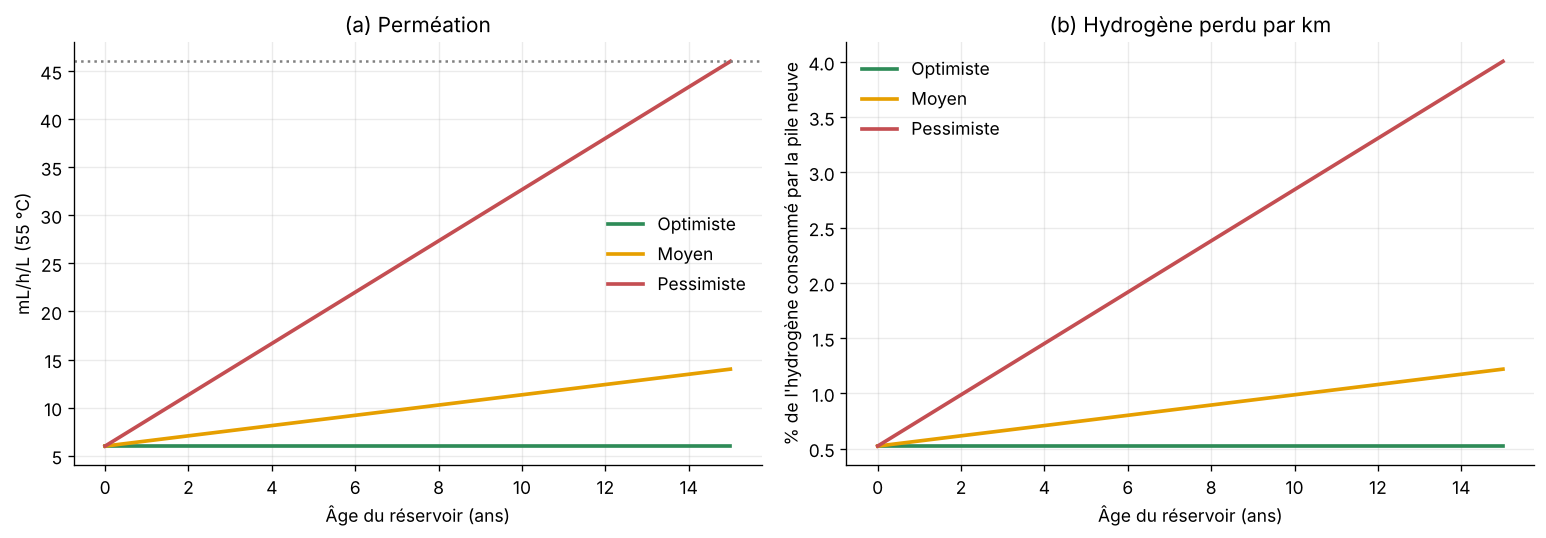

,Perméation à 15 ans (mL/h/L),Perte à 15 ans (g/jour),Perte moyenne sur 15 ans (g/km),Perte moyenne (% de m_FC neuf)
Optimiste,6.000,1.840,0.050,0.522
Moyen,13.999,4.294,0.084,0.871
Pessimiste,45.997,14.109,0.218,2.264


In [7]:
V_RES=142.2;RHO_N=8.988e-8;KM_AN=200000./15.;L_RES=15.   # L ; kg/NmL ; km/an ; ans
RES_SCEN={"Optimiste":(6.,6.),"Moyen":(6.,14.),"Pessimiste":(6.,46.)}
def perm_P(t,sc):
 P0,P1=RES_SCEN[sc] if isinstance(sc,str) else sc;t=np.asarray(t,float);tt=np.mod(t,L_RES);tt=np.where((tt==0)&(t>0),L_RES,tt)   # fin de certification incluse
 return P0+(P1-P0)*tt/L_RES
def perm_km(t,sc):return perm_P(t,sc)*V_RES*RHO_N*8760./KM_AN   # kg H2/km
M0=FC_H2EXP0/DIST
t=np.linspace(0,15,151);fig,axs=plt.subplots(1,2,figsize=(13,4.6))
for sc,c in zip(RES_SCEN,["#2E8B57","#E69F00","#C44E52"]):
 axs[0].plot(t,perm_P(t,sc),color=c,lw=2.2,label=sc);axs[1].plot(t,100*perm_km(t,sc)/M0,color=c,lw=2.2,label=sc)
axs[0].axhline(46,color="grey",ls=":");axs[0].set(xlabel="Âge du réservoir (ans)",ylabel="mL/h/L (55 °C)",title="(a) Perméation");axs[0].legend(frameon=False)
axs[1].set(xlabel="Âge du réservoir (ans)",ylabel="% de l'hydrogène consommé par la pile neuve",title="(b) Hydrogène perdu par km");axs[1].legend(frameon=False)
fig.tight_layout();fig.savefig(OUT/"FAB_01_reservoir.png",dpi=220);plt.show()
res_tab=pd.DataFrame({sc:{"Perméation à 15 ans (mL/h/L)":perm_P(14.999,sc),"Perte à 15 ans (g/jour)":1000*perm_P(14.999,sc)*V_RES*RHO_N*24,
 "Perte moyenne sur 15 ans (g/km)":1000*trapz(perm_km(t,sc),t)/15,"Perte moyenne (% de m_FC neuf)":100*trapz(perm_km(t,sc),t)/15/M0} for sc in RES_SCEN}).T
display(res_tab.round(3))


In [8]:
P_NOM_WE=1250.          # kW : puissance nominale du stack Nel MC250 (NLR, 1,25 MW)
S_WE=1.0                # V14 : l'inventaire (activité peml) est déjà celui du stack de 1,25 MW ; ancien facteur P_NOM_WE/1000     # échelle de l'inventaire (établi pour 1 MW) = puissance nominale / 1 MW
L_VEH=15.;HWE_AN=6000.
_cache={}
def pile_tab(pf,n=61):
 k=("FC",tuple(sorted(pf.items())),n)
 if k not in _cache:
  Tf=fc_eol(pf);a=np.linspace(0,Tf,n);_cache[k]=(Tf,a,np.array([fc_state(x,pf)["H2"] for x in a])/DIST)
 return _cache[k]
def we_tab(pw,n=801):
 k=("WE",tuple(sorted(pw.items())),n)
 if k not in _cache:
  Tw=we_eol(pw);b=np.linspace(0,Tw,n);q=we_state(b,pw)
  _cache[k]=(Tw,b,np.asarray(q["SEC"],float),trapz(np.asarray(q["H2"],float),b)/4.0)   # kg H2 net produits sur la vie
 return _cache[k]
FEv=FE.reindex(IND).to_numpy();EAUv=EAU.reindex(IND).to_numpy();C3v=COMP3.reindex(IND).to_numpy()
def ikg_vec(sec,loss=0,comp=E_COMP,cf=1):return (np.asarray(sec)[:,None]*FEv*cf+EAUv+C3v*comp/3)/(1-loss)
def we_h2_horizon(pw,heures):
 """Hydrogène produit par l'électrolyseur sur l'horizon (kg), stacks successifs repartant de l'état initial."""
 Tw,b,sectab,H2vie=we_tab(pw);nfull=int(heures//Tw);rem=heures-nfull*Tw
 if rem<=0:return nfull*H2vie
 x=np.linspace(0,rem,401);return nfull*H2vie+trapz(np.asarray(we_state(x,pw)["H2"],float),x)/4.0
def vie_vehicule(pf=FC_CENTRAL,pw=WE_CENTRAL,res="Moyen",hwe=HWE_AN,decal=0.,L=L_VEH,s_we=S_WE,discret=True,loss=0,comp=E_COMP,cf=1,npa=80):
 Tf,a,mtab=pile_tab(pf);Tw,b,sectab,H2vie=we_tab(pw)
 t=np.linspace(0,L,int(L*npa)+1);afc=np.mod(t*HFC_AN,Tf);awe=np.mod((t+decal)*hwe,Tw)
 m=np.interp(afc,a,mtab);mp=perm_km(t,res);mt=m+mp;sec=np.interp(awe,b,sectab);ikg=ikg_vec(sec,loss,comp,cf)
 usage=trapz(mt[:,None]*ikg,t,axis=0)/L
 Lkm=L*KM_AN;km_stack=Tf/HFC_AN*KM_AN
 nfc=np.ceil(Lkm/km_stack-1e-9) if discret else Lkm/km_stack   # nombre entier de stacks par défaut (stacks réellement fabriqués)
 nres=np.ceil(L/L_RES-1e-9);mbar=trapz(mt,t)/L
 heures_we=L*hwe;nwe=np.ceil(heures_we/Tw-1e-9) if discret else heures_we/Tw;H2hor=we_h2_horizon(pw,heures_we)
 parts={"Usage":usage,
  "Stacks de pile":nfc*F_STACK_FC.to_numpy()/Lkm,
  "Réservoir":nres*F_RES.to_numpy()/Lkm,
  "Stacks d'électrolyseur":mbar/(1-loss)*s_we*nwe*F_STACK_WE.to_numpy()/H2hor}
 parts={k:pd.Series(v,index=IND) for k,v in parts.items()}
 return {"t":t,"m":m,"mp":mp,"sec":sec,"ikm":mt[:,None]*ikg,"parts":parts,"total":sum(parts.values()),"n_FC":nfc,"km_stack":km_stack,
         "T_FC":Tf,"T_WE":Tw,"H2vie_WE":H2vie,"rempl_WE":int(((L+decal)*hwe)//Tw),"n_WE":nwe,"n_res":nres}
def reference(res="Moyen",hwe=HWE_AN,L=L_VEH,s_we=S_WE,loss=0,comp=E_COMP,cf=1):
 t=np.linspace(0,L,int(L*80)+1);mp=perm_km(t,(RES_SCEN[res][0],)*2);mt=M0+mp;ikg=ikg_vec([WE_SEC0],loss,comp,cf)[0]
 Lkm=L*KM_AN;mbar=trapz(mt,t)/L;H2ref=WE_H20/4.0*hwe*L
 parts={"Usage":mbar*ikg,"Stacks de pile":F_STACK_FC.to_numpy()/Lkm,
  "Réservoir":np.ceil(L/L_RES-1e-9)*F_RES.to_numpy()/Lkm,"Stacks d'électrolyseur":mbar/(1-loss)*s_we*F_STACK_WE.to_numpy()/H2ref}
 parts={k:pd.Series(v,index=IND) for k,v in parts.items()}
 return {"parts":parts,"total":sum(parts.values())}
V=vie_vehicule();REF=reference()
dec=pd.DataFrame({"Avec vieillissement":{k:1000*v[GWP] for k,v in V["parts"].items()},"Sans vieillissement":{k:1000*v[GWP] for k,v in REF["parts"].items()}})
dec.loc["Total"]=dec.sum();dec["Écart (g/km)"]=dec.iloc[:,0]-dec.iloc[:,1]
print(f"Vie du véhicule {L_VEH:.0f} ans = {L_VEH*KM_AN:,.0f} km ; stack de pile : {V['km_stack']:,.0f} km -> {V['n_FC']:.2f} stacks ; électrolyseur : {V['rempl_WE']} remplacement(s) ; H2 produit par stack d'électrolyseur : {V['H2vie_WE']:,.0f} kg")
print("Changement climatique (g CO2-éq/km)");display(dec.round(3))
print(f"Total : {1000*V['total'][GWP]:.2f} g/km avec vieillissement contre {1000*REF['total'][GWP]:.2f} sans (+{100*(V['total'][GWP]/REF['total'][GWP]-1):.1f} %) ; fabrication = {100*(1-V['parts']['Usage'][GWP]/V['total'][GWP]):.0f} % du total")


Vie du véhicule 15 ans = 200,000 km ; stack de pile : 137,831 km -> 2.00 stacks ; électrolyseur : 1 remplacement(s) ; H2 produit par stack d'électrolyseur : 613,632 kg
Changement climatique (g CO2-éq/km)


,Avec vieillissement,Sans vieillissement,Écart (g/km)
Usage,49.069,43.649,5.419
Stacks de pile,36.983,18.492,18.492
Réservoir,11.660,11.660,0.000
Stacks d'électrolyseur,0.682,0.322,0.360
Total,98.394,74.123,24.271


Total : 98.39 g/km avec vieillissement contre 74.12 sans (+32.7 %) ; fabrication = 50 % du total


## 1. Facteurs de normalisation et de pondération

| Catégorie EF 3.1 | Indicateur du notebook | Unité | NF (/personne) | WF (%) |
|---|---|---|---:|---:|
| Acidification | Acidification | mol H⁺ éq | 55,6 | 6,20 |
| Changement climatique | Changement climatique | kg CO₂ éq | 7 550 | 21,06 |
| Écotoxicité de l'eau douce | Écotoxicité totale | CTUe | 56 700 | 1,92 |
| Particules fines | Particules | incidence de maladie | 5,95×10⁻⁴ | 8,96 |
| Eutrophisation eau douce | Eutrophisation eau douce | kg P éq | 1,61 | 2,80 |
| Eutrophisation marine | Eutrophisation marine | kg N éq | 19,5 | 2,96 |
| Eutrophisation terrestre | Eutrophisation terrestre | mol N éq | 177 | 3,71 |
| Toxicité humaine cancérigène | Toxicité humaine totale | CTUh | 1,73×10⁻⁵ | 2,13 |
| Appauvrissement de la couche d'ozone | Ozone | kg CFC-11 éq | 0,0523 | 6,31 |
| Ressources énergétiques non renouvelables | Énergie fossile | MJ | 65 000 | 8,32 |
| Ressources minérales | Ressources minérales | kg Sb éq | 0,0636 | 7,55 |
| Ressources en eau | Utilisation de l'eau | m³ monde éq | 11 500 | 8,51 |
| Toxicité humaine non cancérigène | *fabrication seulement* | CTUh | 1,29×10⁻⁴ | 1,84 |
| Radiations ionisantes | *fabrication seulement* | kBq U235 éq | 4 220 | 5,01 |
| Usage des terres | *fabrication seulement* | pt | 819 000 | 7,94 |
| Formation photochimique d'ozone | *fabrication seulement* | kg NMVOC éq | 40,9 | 4,78 |


In [9]:
EF=pd.DataFrame([
 ("Acidification","Acidification","mol H+ éq",55.6,6.20),
 ("Changement climatique","Changement climatique","kg CO2 éq",7550.,21.06),
 ("Écotoxicité totale","Écotoxicité eau douce","CTUe",56700.,1.92),
 ("Particules","Particules fines","incidence",5.95e-4,8.96),
 ("Eutrophisation eau douce","Eutrophisation eau douce","kg P éq",1.61,2.80),
 ("Eutrophisation marine","Eutrophisation marine","kg N éq",19.5,2.96),
 ("Eutrophisation terrestre","Eutrophisation terrestre","mol N éq",177.,3.71),
 ("Toxicité humaine totale","Toxicité humaine cancérigène","CTUh",1.73e-5,2.13),
 ("Ozone","Couche d'ozone","kg CFC-11 éq",0.0523,6.31),
 ("Énergie fossile","Ressources énergétiques","MJ",65000.,8.32),
 ("Ressources minérales","Ressources minérales","kg Sb éq",0.0636,7.55),
 ("Utilisation de l'eau","Ressources en eau","m3 monde éq",11500.,8.51),
 ("Usage des terres","Usage des terres","pt",819000.,7.94),("Radiations ionisantes","Radiations ionisantes","kBq U235 éq",4220.,5.01),
 ("Formation photochimique d'ozone","Formation photochimique d'ozone","kg NMVOC éq",40.9,4.78),("Toxicité humaine non cancérigène","Toxicité humaine non cancérigène","CTUh",1.29e-4,1.84)],
 columns=["Indicateur","Catégorie EF","Unité","NF","WF_pct"]).set_index("Indicateur")
MANQUANTES={}   # V11 : les 16 catégories sont couvertes (inventaire de l'eau complet)
EF4=pd.DataFrame([("Toxicité humaine non cancérigène","CTUh",1.29e-4,1.84),("Radiations ionisantes","kBq U235 éq",4220.,5.01),
 ("Usage des terres","pt",819000.,7.94),("Formation photochimique d'ozone","kg NMVOC éq",40.9,4.78)],columns=["Catégorie EF","Unité","NF","WF_pct"]).set_index("Catégorie EF")
EF16=EF.set_index("Catégorie EF")[["Unité","NF","WF_pct"]];assert abs(EF16.WF_pct.sum()-100)<1e-9
# Fabrication sur les 16 catégories (Brightway, ecoinvent 3.11 cut-off) : fichiers pile.xlsx, peml.xlsx, reservoir.xlsx
FAB16=pd.DataFrame({"Stack de pile (128 kW)": {"Acidification": 260.1519538833514, "Changement climatique": 7433.43743851008, "Écotoxicité eau douce": 69567.60160354408, "Ressources énergétiques": 75698.40567294328, "Eutrophisation eau douce": 4.78053595844442, "Eutrophisation marine": 18.97491309036641, "Eutrophisation terrestre": 267.7069368698439, "Toxicité humaine cancérigène": 2.824620617295487e-06, "Toxicité humaine non cancérigène": 7.223935284394861e-05, "Radiations ionisantes": 329.9390378455433, "Usage des terres": 31383.32238881429, "Ressources minérales": 0.2209245325401167, "Couche d'ozone": 0.0305485554869168, "Particules fines": 0.000694520160191913, "Formation photochimique d'ozone": 70.77345779757499, "Ressources en eau": 1695.055810718058}, "Stack d'électrolyseur (1 MW)": {"Acidification": 3525.037161324252, "Changement climatique": 76481.90785513633, "Écotoxicité eau douce": 938255.3251941013, "Ressources énergétiques": 957636.8609624219, "Eutrophisation eau douce": 67.72206898190822, "Eutrophisation marine": 258.3627754221697, "Eutrophisation terrestre": 3643.123055020206, "Toxicité humaine cancérigène": 4.796978261616523e-05, "Toxicité humaine non cancérigène": 0.0008159193948438355, "Radiations ionisantes": 3610.801062275642, "Usage des terres": 494875.3762569571, "Ressources minérales": 2.259033694745131, "Couche d'ozone": 0.07114769429467616, "Particules fines": 0.01078867136866144, "Formation photochimique d'ozone": 974.5793625919089, "Ressources en eau": 14893.26611047897}, "Réservoir": {"Acidification": 11.68682895027511, "Changement climatique": 2075.004780841748, "Écotoxicité eau douce": 10675.81443876609, "Ressources énergétiques": 28566.34013265822, "Eutrophisation eau douce": 0.7259791193127696, "Eutrophisation marine": 2.336832635294235, "Eutrophisation terrestre": 21.20158628390095, "Toxicité humaine cancérigène": 5.32054990554701e-07, "Toxicité humaine non cancérigène": 1.603258346830262e-05, "Radiations ionisantes": 161.8019953358707, "Usage des terres": 7520.780972642723, "Ressources minérales": 0.00891014103732108, "Couche d'ozone": 2.336157474084723e-05, "Particules fines": 0.0001547371907187039, "Formation photochimique d'ozone": 6.665922006670208, "Ressources en eau": 449.7196840839306}}).reindex(EF16.index)
# V5 : stack de pile = inventaire de Mori et al. (2023) mis à l'échelle de 128 kW ; stack d'électrolyseur = inventaire de Lundberg (2019), 1 MW
FAB16["Stack de pile (128 kW)"]=pd.Series({"Acidification": 248.6582735672424, "Changement climatique": 3698.346742156322, "Écotoxicité eau douce": 67995.96210221738, "Ressources énergétiques": 64984.53610733856, "Eutrophisation eau douce": 4.27016797780295, "Eutrophisation marine": 17.16909518528825, "Eutrophisation terrestre": 248.604010366358, "Toxicité humaine cancérigène": 1.38979620550576e-06, "Toxicité humaine non cancérigène": 6.484218704562489e-05, "Radiations ionisantes": 843.8269015738455, "Usage des terres": 28190.78931979666, "Ressources minérales": 0.1838955299372942, "Couche d'ozone": 0.00169092666370126, "Particules fines": 0.0005863685653156342, "Formation photochimique d'ozone": 64.3280624097413, "Ressources en eau": 962.4103658170666}).reindex(EF16.index)
FAB16["Stack d'électrolyseur (1 MW)"]=pd.Series({"Acidification": 541.9303241901652, "Changement climatique": 39509.356138025, "Écotoxicité eau douce": 202177.3298567108, "Ressources énergétiques": 516877.16421177, "Eutrophisation eau douce": 22.06169155923207, "Eutrophisation marine": 57.84338021425834, "Eutrophisation terrestre": 694.5467872386303, "Toxicité humaine cancérigène": 4.108245023556852e-05, "Toxicité humaine non cancérigène": 0.0003593609038317293, "Radiations ionisantes": 6417.527789075928, "Usage des terres": 190158.3583246214, "Ressources minérales": 0.4318232282350359, "Couche d'ozone": 0.07093678234215871, "Particules fines": 0.004230264548149397, "Formation photochimique d'ozone": 217.500524451658, "Ressources en eau": 8454.03905835908}).reindex(EF16.index)
FAB16["Réservoir"]=pd.Series({"Acidification": 12.84867086932092, "Changement climatique": 2332.026270158021, "Écotoxicité eau douce": 11178.11535018604, "Ressources énergétiques": 32049.23050780235, "Eutrophisation eau douce": 0.8354225138274014, "Eutrophisation marine": 2.582498258236369, "Eutrophisation terrestre": 23.66687466869964, "Toxicité humaine cancérigène": 5.593504833465078e-07, "Toxicité humaine non cancérigène": 1.729651533295304e-05, "Radiations ionisantes": 193.9538005168125, "Usage des terres": 7952.628710906571, "Ressources minérales": 0.00902534451608675, "Couche d'ozone": 2.573331900733087e-05, "Particules fines": 0.0001653445622898199, "Formation photochimique d'ozone": 7.416588486848695, "Ressources en eau": 508.0363394698326}).reindex(EF16.index)
def score16(s,mode="complet"):
 w=EF16.WF_pct/100. if mode=="complet" else pd.Series(1/16,index=EF16.index)
 return float((s.reindex(EF16.index)/EF16.NF*w).sum())
def fab16_part(part,F12,F16s):
 # partie de fabrication par km sur 16 catégories : même répartition que sur le changement climatique
 return F16s*(part[GWP]/F12[GWP])
CATS=list(EF.index);LAB=EF["Catégorie EF"].to_dict()
WF_PRESENT=EF.WF_pct.sum()
print(f"Poids couverts : {WF_PRESENT:.2f} % ; manquants : {sum(MANQUANTES.values()):.2f} % ; total {WF_PRESENT+sum(MANQUANTES.values()):.2f} %")
def normaliser(s):
 s=pd.Series(s,index=IND) if not isinstance(s,pd.Series) else s
 return (s.reindex(CATS)/EF.NF).rename(index=LAB)                # personne-équivalent
def ponderer(s,mode="partiel"):
 w=EF.WF_pct/100. if mode=="partiel" else (EF.WF_pct/WF_PRESENT if mode=="renormalise" else pd.Series(1/len(CATS),index=CATS))
 return normaliser(s)*w.rename(index=LAB)                        # Pt
def score(s,mode="partiel"):return float(ponderer(s,mode).sum())
UPT=1e6   # µPt
display(EF)


Poids couverts : 100.00 % ; manquants : 0.00 % ; total 100.00 %


,Catégorie EF,Unité,NF,WF_pct
Indicateur,,,,
Acidification,Acidification,mol H+ éq,55.600000,6.20
Changement climatique,Changement climatique,kg CO2 éq,7550.000000,21.06
Écotoxicité totale,Écotoxicité eau douce,CTUe,56700.000000,1.92
Particules,Particules fines,incidence,0.000595,8.96
Eutrophisation eau douce,Eutrophisation eau douce,kg P éq,1.610000,2.80
Eutrophisation marine,Eutrophisation marine,kg N éq,19.500000,2.96
Eutrophisation terrestre,Eutrophisation terrestre,mol N éq,177.000000,3.71
Toxicité humaine totale,Toxicité humaine cancérigène,CTUh,0.000017,2.13
Ozone,Couche d'ozone,kg CFC-11 éq,0.052300,6.31


## 2. Fabrication d'une unité de chaque composant (16 catégories)

Score unique **complet** (16 catégories EF, 100 % des poids) de la fabrication d'un stack de pile (128 kW), d'un stack d'électrolyseur (1 MW) et d'un réservoir, avant toute répartition par km. Le score sur les 12 catégories communes avec l'usage est donné pour comparaison, ainsi que le score par kW de stack.

,Score unique 16 cat. (Pt),Score unique 12 cat. (Pt),Part des 4 catégories ajoutées (%),Changement climatique (kg CO2 éq),Catégorie dominante,Part de la catégorie dominante (%),Score par kW (mPt/kW)
Stack de pile (128 kW),1.054,1.054,0.0,3698.347,Acidification,26.314,8.232
Stack d'électrolyseur (1 MW),4.802,4.802,0.0,39509.356,Changement climatique,22.951,4.802
Réservoir,0.202,0.202,0.0,2332.026,Changement climatique,32.219,NaN


Normalisé (personne-éq) :


,Stack de pile (128 kW),Stack d'électrolyseur (1 MW),Réservoir
Catégorie EF,,,
Acidification,4.4723,9.7469,0.2311
Changement climatique,0.4898,5.2330,0.3089
Écotoxicité eau douce,1.1992,3.5657,0.1971
Particules fines,0.9855,7.1097,0.2779
Eutrophisation eau douce,2.6523,13.7029,0.5189
Eutrophisation marine,0.8805,2.9663,0.1324
Eutrophisation terrestre,1.4045,3.9240,0.1337
Toxicité humaine cancérigène,0.0803,2.3747,0.0323
Couche d'ozone,0.0323,1.3563,0.0005


Pondéré (Pt) :


,Stack de pile (128 kW),Stack d'électrolyseur (1 MW),Réservoir
Catégorie EF,,,
Acidification,0.2773,0.6043,0.0143
Changement climatique,0.1032,1.1021,0.0650
Écotoxicité eau douce,0.0230,0.0685,0.0038
Particules fines,0.0883,0.6370,0.0249
Eutrophisation eau douce,0.0743,0.3837,0.0145
Eutrophisation marine,0.0261,0.0878,0.0039
Eutrophisation terrestre,0.0521,0.1456,0.0050
Toxicité humaine cancérigène,0.0017,0.0506,0.0007
Couche d'ozone,0.0020,0.0856,0.0000


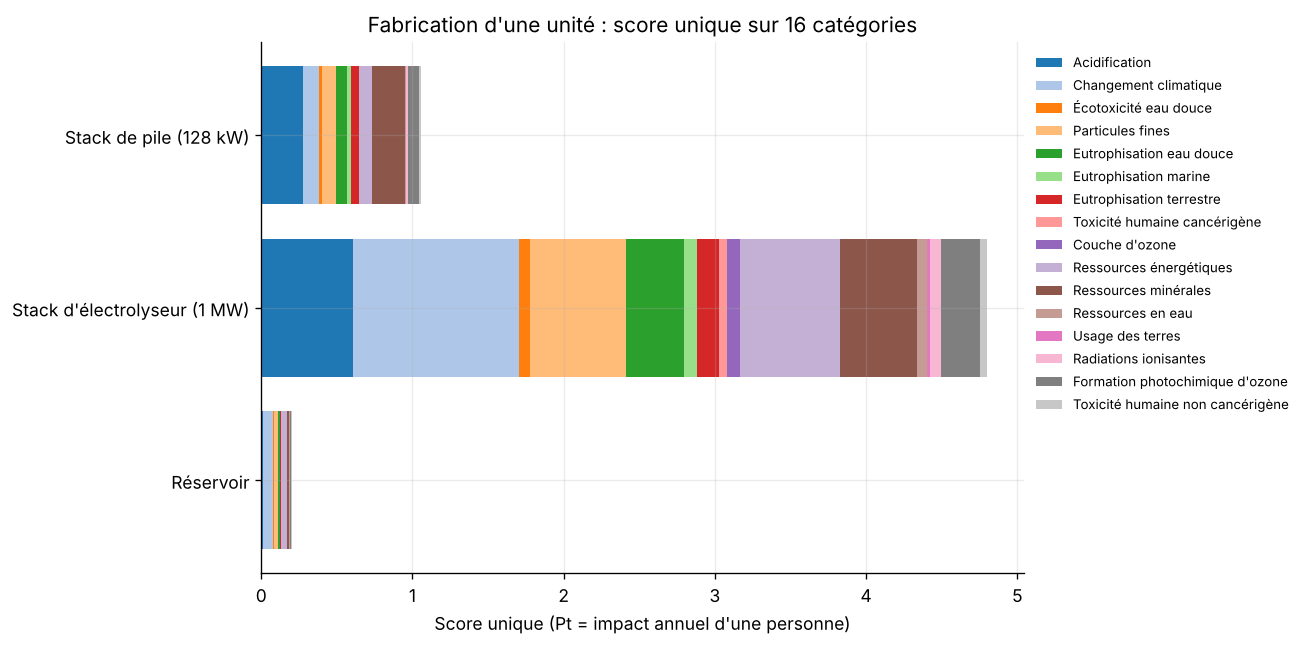

In [10]:
FAB_U={"Stack de pile (128 kW)":F_STACK_FC,"Stack d'électrolyseur (1 MW)":F_STACK_WE,"Réservoir":F_RES}
fab_norm=FAB16.div(EF16.NF,axis=0)
fab_pond=fab_norm.mul(EF16.WF_pct/100.,axis=0)
fab_tab=pd.DataFrame({"Score unique 16 cat. (Pt)":fab_pond.sum(),"Score unique 12 cat. (Pt)":[score(v) for v in FAB_U.values()],
 "Part des 4 catégories ajoutées (%)":100*fab_pond.loc[list(MANQUANTES)].sum()/fab_pond.sum(),
 "Changement climatique (kg CO2 éq)":FAB16.loc["Changement climatique"],
 "Catégorie dominante":fab_pond.idxmax(),"Part de la catégorie dominante (%)":100*fab_pond.max()/fab_pond.sum()})
fab_tab["Score par kW (mPt/kW)"]=1000*fab_tab["Score unique 16 cat. (Pt)"]/pd.Series({"Stack de pile (128 kW)":128.,"Stack d'électrolyseur (1 MW)":1000.,"Réservoir":np.nan})
display(fab_tab.round(3));print("Normalisé (personne-éq) :");display(fab_norm.round(4));print("Pondéré (Pt) :");display(fab_pond.round(4))
fig,ax=plt.subplots(figsize=(11,5.5));left=np.zeros(3);cmap=plt.get_cmap("tab20")
for i,c in enumerate(fab_pond.index):
 v=fab_pond.loc[c].to_numpy();ax.barh(list(FAB_U),v,left=left,color=cmap(i),label=c);left+=v
ax.set(xlabel="Score unique (Pt = impact annuel d'une personne)",title="Fabrication d'une unité : score unique sur 16 catégories");ax.invert_yaxis()
ax.legend(frameon=False,fontsize=8,bbox_to_anchor=(1,1));fig.tight_layout();fig.savefig(OUT/"NW_01_fabrication_unite.png",dpi=220);plt.show()


## 3. Un kilogramme d'hydrogène livré

Impact d'un kg d'hydrogène livré au véhicule : électricité de l'électrolyseur, eau, compression et fabrication du stack d'électrolyseur (répartie sur sa vie). Comparaison électrolyseur neuf, à mi-vie et en fin de vie.

,Électricité,Eau,Compression,Fabrication stack électrolyseur,Total (µPt/kg),SEC (kWh/kg),CO2 (kg/kg),Hausse score (%)
Neuf,1686.254,0.881,87.964,7.825,1782.925,53.676,4.567,0.000
Mi-vie,1802.668,0.881,87.964,7.825,1899.339,57.381,4.862,6.529
Fin de vie,1900.802,0.881,87.964,7.825,1997.472,60.505,5.111,12.033


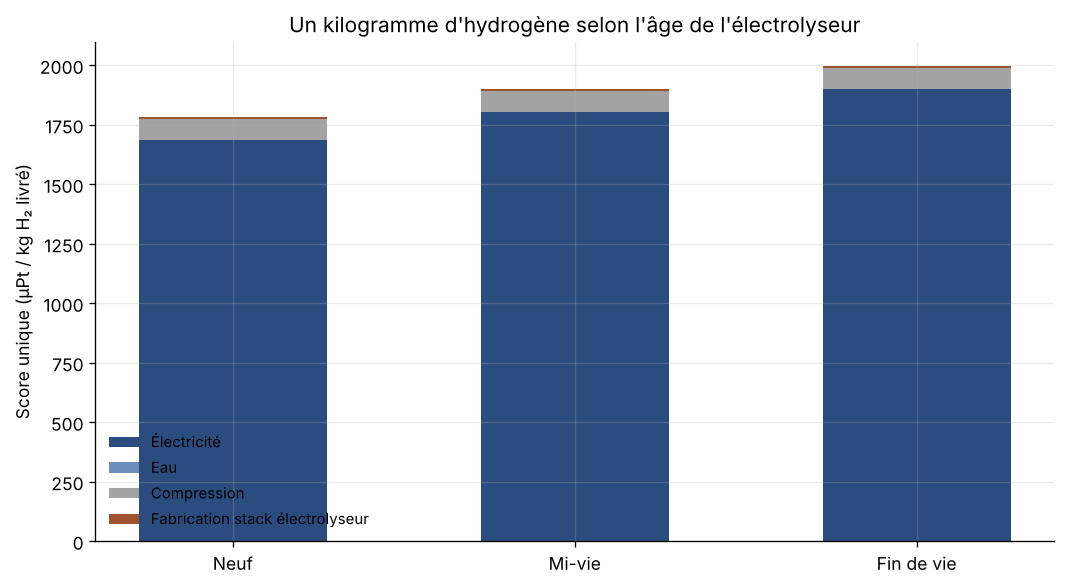

In [11]:
Tw,b,sectab,H2vie=we_tab(WE_CENTRAL);FABWE_KG=S_WE*F_STACK_WE/H2vie
def kg_parts(sec,cf=1,comp=E_COMP):return {"Électricité":pd.Series(sec*FE.reindex(IND).to_numpy()*cf,index=IND),"Eau":EAU.reindex(IND),
 "Compression":COMP3.reindex(IND)*comp/3,"Fabrication stack électrolyseur":FABWE_KG}
etats={"Neuf":WE_SEC0,"Mi-vie":float(np.interp(Tw/2,b,sectab)),"Fin de vie":float(np.interp(Tw,b,sectab))}
kg=pd.DataFrame({e:{p:UPT*score(v) for p,v in kg_parts(s).items()} for e,s in etats.items()}).T
kg["Total (µPt/kg)"]=kg.sum(axis=1);kg["SEC (kWh/kg)"]=list(etats.values());kg["CO2 (kg/kg)"]=[sum(kg_parts(s).values())[GWP] for s in etats.values()]
kg["Hausse score (%)"]=100*(kg["Total (µPt/kg)"]/kg.loc["Neuf","Total (µPt/kg)"]-1);display(kg.round(3))
fig,ax=plt.subplots(figsize=(9,5));bot=np.zeros(3);cols4=["#2B4C7E","#6C8EBF","#A3A3A3","#A0522D"]
for p,c in zip(["Électricité","Eau","Compression","Fabrication stack électrolyseur"],cols4):
 ax.bar(kg.index,kg[p],bottom=bot,color=c,label=p,width=.55);bot+=kg[p].to_numpy()
ax.set(ylabel="Score unique (µPt / kg H₂ livré)",title="Un kilogramme d'hydrogène selon l'âge de l'électrolyseur");ax.legend(frameon=False,fontsize=9)
fig.tight_layout();fig.savefig(OUT/"NW_02_kg_H2.png",dpi=220);plt.show()


## 4. Un kilomètre sur la vie du véhicule : postes, catégories et effet du vieillissement

Six postes : électricité, eau et compression (usage), stacks de pile, réservoir, stacks d'électrolyseur (fabrication). Cas central, avec et sans vieillissement.

In [12]:
def detail(pf=FC_CENTRAL,pw=WE_CENTRAL,cf=1.,comp=E_COMP,loss=0.,**kw):
 v=vie_vehicule(pf,pw,cf=cf,comp=comp,loss=loss,**kw);t=v["t"];L=t[-1];mt=v["m"]+v["mp"];mbar=trapz(mt,t)/L
 elec=trapz(mt*v["sec"],t)/L*FE.reindex(IND)*cf/(1-loss)
 P={"Électricité":elec,"Eau":mbar*EAU.reindex(IND)/(1-loss),"Compression":mbar*COMP3.reindex(IND)*comp/3/(1-loss),
    "Stacks de pile":v["parts"]["Stacks de pile"],"Réservoir":v["parts"]["Réservoir"],"Stacks d'électrolyseur":v["parts"]["Stacks d'électrolyseur"]}
 assert np.allclose(sum(P.values()),v["total"],rtol=1e-6)
 return P,v
def detail_ref(cf=1.,comp=E_COMP,loss=0.,**kw):
 r=reference(cf=cf,comp=comp,loss=loss,**{k:kw[k] for k in kw if k in ("res","hwe","L","s_we")});u=r["parts"]["Usage"];ikg=ikg_vec([WE_SEC0],loss,comp,cf)[0]
 mbar=float(u[GWP]/ikg[IND.index(GWP)])
 P={"Électricité":mbar*WE_SEC0*FE.reindex(IND)*cf/(1-loss),"Eau":mbar*EAU.reindex(IND)/(1-loss),"Compression":mbar*COMP3.reindex(IND)*comp/3/(1-loss),
    "Stacks de pile":r["parts"]["Stacks de pile"],"Réservoir":r["parts"]["Réservoir"],"Stacks d'électrolyseur":r["parts"]["Stacks d'électrolyseur"]}
 assert np.allclose(sum(P.values()),r["total"],rtol=1e-6);return P
POSTES=["Électricité","Eau","Compression","Stacks de pile","Réservoir","Stacks d'électrolyseur"]
PCOL=["#2B4C7E","#6C8EBF","#A3A3A3","#A0522D","#7F7F7F","#E69F00"]
PA,VA=detail();PR=detail_ref()
TA=sum(PA.values());TR=sum(PR.values())
car=pd.DataFrame({"Sans vieillissement":TR,"Avec vieillissement":TA});car["Hausse (%)"]=100*(car.iloc[:,1]/car.iloc[:,0]-1)
print("Résultats caractérisés par km (unités de chaque indicateur)");display(car)
nor=pd.DataFrame({"Sans vieillissement":normaliser(TR),"Avec vieillissement":normaliser(TA)})*UPT
print("Normalisés (µ personne-équivalent par km)");display(nor.round(4))
pon=pd.DataFrame({"Sans vieillissement":ponderer(TR),"Avec vieillissement":ponderer(TA)})*UPT
pon["Écart (µPt/km)"]=pon.iloc[:,1]-pon.iloc[:,0];pon["Part du score avec vieillissement (%)"]=100*pon.iloc[:,1]/pon.iloc[:,1].sum()
pon=pon.sort_values("Avec vieillissement",ascending=False);print("Pondérés (µPt par km)");display(pon.round(4))
SU_A=UPT*score(TA);SU_R=UPT*score(TR)
print(f"Score unique : {SU_R:.3f} µPt/km sans vieillissement ; {SU_A:.3f} µPt/km avec (+{100*(SU_A/SU_R-1):.1f} %)")
print(f"Sur la vie du véhicule ({L_VEH*KM_AN:,.0f} km) : {SU_R*L_VEH*KM_AN/UPT:.3f} Pt contre {SU_A*L_VEH*KM_AN/UPT:.3f} Pt, soit l'impact annuel de {SU_A*L_VEH*KM_AN/UPT:.2f} personne")
print(f"Pour comparaison, changement climatique : +{100*(TA[GWP]/TR[GWP]-1):.1f} %")


Résultats caractérisés par km (unités de chaque indicateur)


,Sans vieillissement,Avec vieillissement,Hausse (%)
Acidification,1.455545e-03,2.721590e-03,86.980866
Changement climatique,7.412261e-02,9.839410e-02,32.745063
Écotoxicité totale,4.912620e-01,8.443939e-01,71.882611
Écotoxicité inorganique,4.832413e-01,8.339537e-01,72.574989
Écotoxicité organique,8.020613e-03,1.044018e-02,30.166881
Énergie fossile,8.151139e+00,9.432553e+00,15.720678
Eutrophisation eau douce,3.184777e-05,5.416130e-05,70.063052
Eutrophisation marine,1.539010e-04,2.470629e-04,60.533600
Eutrophisation terrestre,1.734985e-03,3.030021e-03,74.642494
Toxicité humaine totale,2.295014e-11,3.186631e-11,38.850195


Normalisés (µ personne-équivalent par km)


,Sans vieillissement,Avec vieillissement
Acidification,26.1789,48.9495
Changement climatique,9.8176,13.0323
Écotoxicité eau douce,8.6642,14.8923
Particules fines,10.5501,16.0607
Eutrophisation eau douce,19.7812,33.6406
Eutrophisation marine,7.8924,12.6699
Eutrophisation terrestre,9.8022,17.1188
Toxicité humaine cancérigène,1.3266,1.8420
Couche d'ozone,0.2003,0.3775
Ressources énergétiques,125.4021,145.1162


Pondérés (µPt par km)


,Sans vieillissement,Avec vieillissement,Écart (µPt/km),Part du score avec vieillissement (%)
Ressources énergétiques,10.4335,12.0737,1.6402,38.9781
Radiations ionisantes,4.2059,4.7714,0.5655,15.4038
Acidification,1.6231,3.0349,1.4118,9.7976
Changement climatique,2.0676,2.7446,0.6770,8.8606
Ressources minérales,1.5743,2.7231,1.1488,8.7913
Particules fines,0.9453,1.4390,0.4938,4.6457
Formation photochimique d'ozone,0.5789,0.9767,0.3978,3.1530
Eutrophisation eau douce,0.5539,0.9419,0.3881,3.0409
Ressources en eau,0.5768,0.6778,0.1010,2.1882
Eutrophisation terrestre,0.3637,0.6351,0.2714,2.0504


Score unique : 23.526 µPt/km sans vieillissement ; 30.975 µPt/km avec (+31.7 %)
Sur la vie du véhicule (200,000 km) : 4.705 Pt contre 6.195 Pt, soit l'impact annuel de 6.20 personne
Pour comparaison, changement climatique : +32.7 %


,Sans vieillissement,Avec vieillissement,Écart (µPt/km),Part avec vieillissement (%)
Électricité,16.347,18.436,2.088,59.517
Eau,0.009,0.009,0.000,0.029
Compression,0.853,0.901,0.048,2.909
Stacks de pile,5.269,10.537,5.269,34.018
Réservoir,1.009,1.009,0.000,3.259
Stacks d'électrolyseur,0.039,0.083,0.044,0.268
Total,23.526,30.975,7.450,100.000


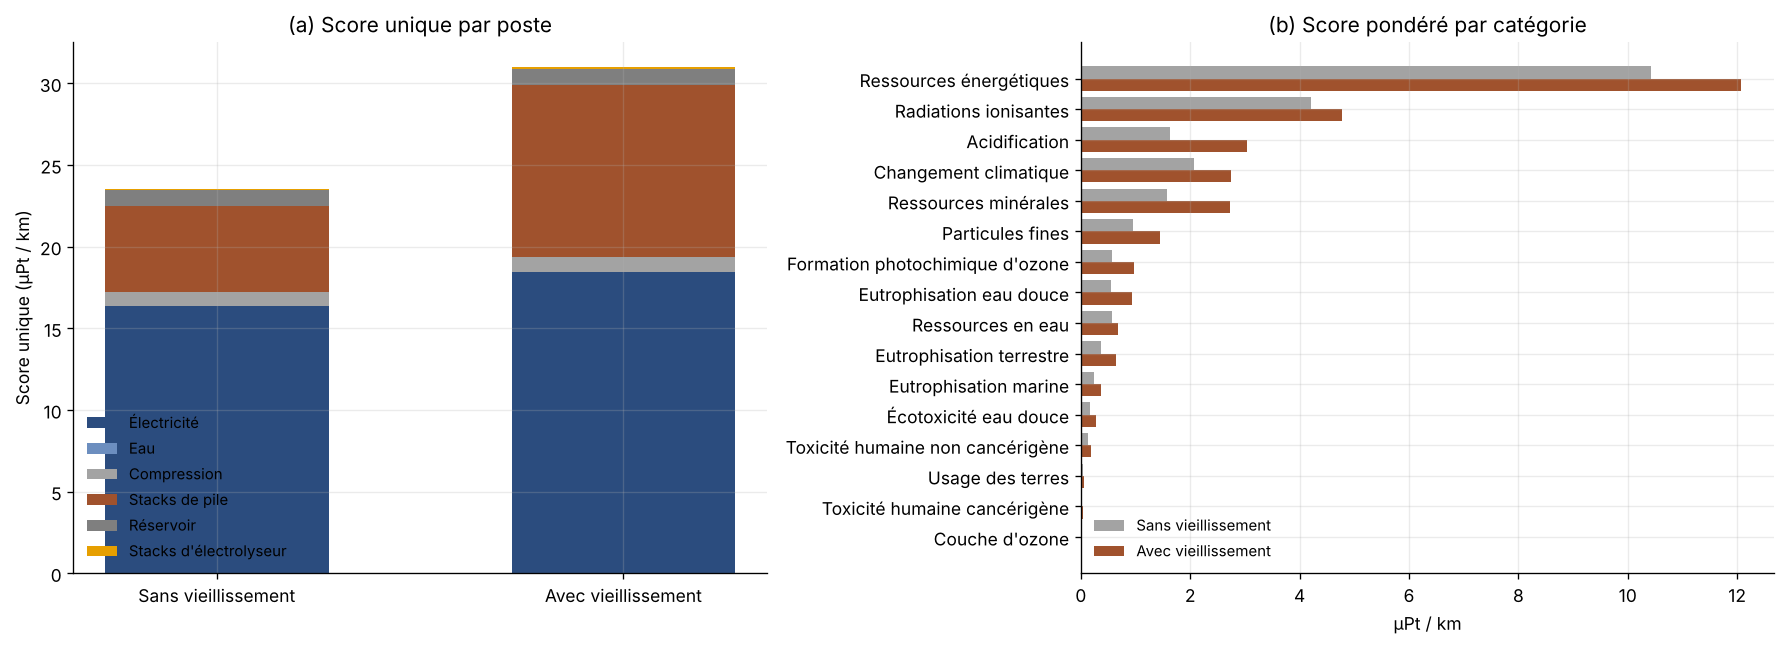

In [13]:
post=pd.DataFrame({p:{"Sans vieillissement":UPT*score(PR[p]),"Avec vieillissement":UPT*score(PA[p])} for p in POSTES}).T
post["Écart (µPt/km)"]=post.iloc[:,1]-post.iloc[:,0];post["Part avec vieillissement (%)"]=100*post.iloc[:,1]/post.iloc[:,1].sum()
post.loc["Total"]=post.sum();post.loc["Total","Part avec vieillissement (%)"]=100;display(post.round(3))
fig,axs=plt.subplots(1,2,figsize=(15,5.5))
bot=np.zeros(2)
for p,c in zip(POSTES,PCOL):
 v=post.loc[p,["Sans vieillissement","Avec vieillissement"]].to_numpy(float);axs[0].bar(["Sans vieillissement","Avec vieillissement"],v,bottom=bot,color=c,label=p,width=.55);bot+=v
axs[0].set(ylabel="Score unique (µPt / km)",title="(a) Score unique par poste");axs[0].legend(frameon=False,fontsize=9)
x=np.arange(len(pon));axs[1].barh(x-.2,pon["Sans vieillissement"],height=.4,color="#A3A3A3",label="Sans vieillissement")
axs[1].barh(x+.2,pon["Avec vieillissement"],height=.4,color="#A0522D",label="Avec vieillissement");axs[1].set_yticks(x,pon.index);axs[1].invert_yaxis()
axs[1].set(xlabel="µPt / km",title="(b) Score pondéré par catégorie");axs[1].legend(frameon=False,fontsize=9)
fig.tight_layout();fig.savefig(OUT/"NW_03_score_postes_categories.png",dpi=220);plt.show()


### Matrice postes × catégories

Part de chaque couple (poste, catégorie) dans le score unique avec vieillissement : elle montre où se concentre l'impact.

,Électricité,Eau,Compression,Stacks de pile,Réservoir,Stacks d'électrolyseur
Acidification,0.55,0.00,0.03,8.95,0.23,0.03
Changement climatique,4.21,0.00,0.21,3.33,1.05,0.06
Écotoxicité eau douce,0.10,0.01,0.01,0.74,0.06,0.00
Particules fines,1.29,0.00,0.06,2.85,0.40,0.04
Eutrophisation eau douce,0.37,0.00,0.02,2.40,0.23,0.02
Eutrophisation marine,0.29,0.00,0.01,0.84,0.06,0.00
Eutrophisation terrestre,0.27,0.00,0.01,1.68,0.08,0.01
Toxicité humaine cancérigène,0.05,0.00,0.00,0.06,0.01,0.00
Couche d'ozone,0.01,0.00,0.00,0.07,0.00,0.00
Ressources énergétiques,33.93,0.00,1.66,2.69,0.66,0.04


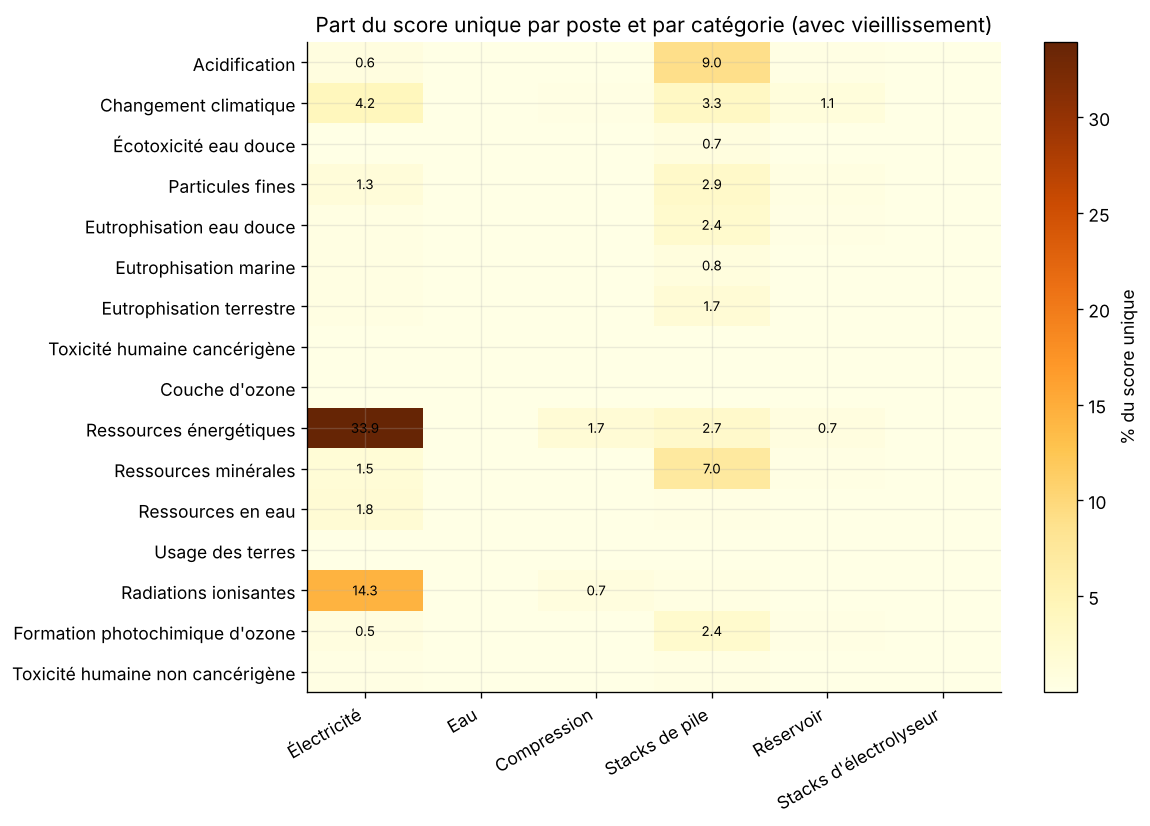

Dix couples les plus contributeurs


% du score
Ressources énergétiques         Électricité          33.93
Radiations ionisantes           Électricité          14.34
Acidification                   Stacks de pile        8.95
Ressources minérales            Stacks de pile        7.05
Changement climatique           Électricité           4.21
                                Stacks de pile        3.33
Particules fines                Stacks de pile        2.85
Ressources énergétiques         Stacks de pile        2.69
Formation photochimique d'ozone Stacks de pile        2.43
Eutrophisation eau douce        Stacks de pile        2.40

In [14]:
mat_pc=pd.DataFrame({p:UPT*ponderer(PA[p]) for p in POSTES})
part_pc=100*mat_pc/mat_pc.values.sum();display(part_pc.round(2))
fig,ax=plt.subplots(figsize=(10,7));im=ax.imshow(part_pc,cmap="YlOrBr",aspect="auto")
ax.set_xticks(range(len(POSTES)),POSTES,rotation=30,ha="right");ax.set_yticks(range(len(part_pc)),part_pc.index)
for i in range(part_pc.shape[0]):
 for j in range(part_pc.shape[1]):
  v=part_pc.iat[i,j]
  if v>=0.5:ax.text(j,i,f"{v:.1f}",ha="center",va="center",fontsize=8)
fig.colorbar(im,ax=ax,label="% du score unique");ax.set_title("Part du score unique par poste et par catégorie (avec vieillissement)")
fig.tight_layout();fig.savefig(OUT/"NW_04_matrice_postes_categories.png",dpi=220);plt.show()
top=part_pc.stack().sort_values(ascending=False).head(10).rename("% du score").to_frame();print("Dix couples les plus contributeurs");display(top.round(2))


## 5. D'où vient l'effet du vieillissement ?

Écart de score unique entre la chaîne vieillissante et la référence, décomposé par poste.

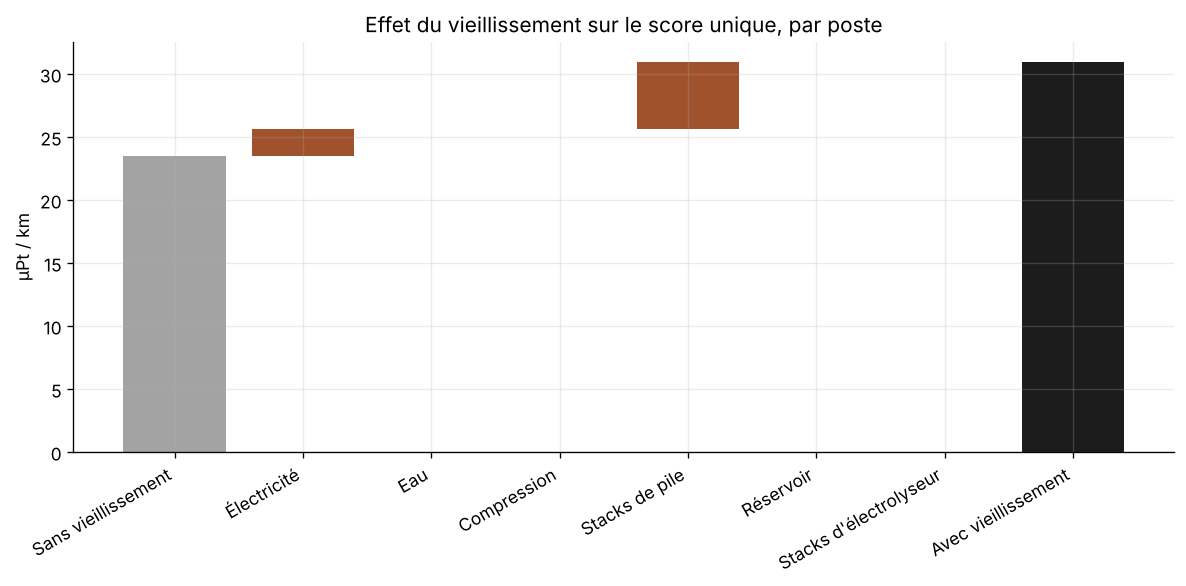

,Écart (µPt/km),Part de l'écart (%)
Électricité,2.088,28.033
Eau,0.000,0.007
Compression,0.048,0.649
Stacks de pile,5.269,70.723
Réservoir,0.000,0.000
Stacks d'électrolyseur,0.044,0.588


In [15]:
ecart=post.drop("Total")["Écart (µPt/km)"]
fig,ax=plt.subplots(figsize=(10,5));cum=SU_R;xs=["Sans vieillissement"]+POSTES+["Avec vieillissement"]
ax.bar(0,SU_R,color="#A3A3A3")
for i,p in enumerate(POSTES,1):
 d=ecart[p];ax.bar(i,d,bottom=cum if d>=0 else cum+d,color="#A0522D" if d>0 else "#2E8B57");cum+=d
ax.bar(len(POSTES)+1,SU_A,color="#1C1C1C");ax.set_xticks(range(len(xs)),xs,rotation=30,ha="right")
ax.set(ylabel="µPt / km",title="Effet du vieillissement sur le score unique, par poste");fig.tight_layout();fig.savefig(OUT/"NW_05_cascade_vieillissement.png",dpi=220);plt.show()
dec_v=pd.DataFrame({"Écart (µPt/km)":ecart,"Part de l'écart (%)":100*ecart/ecart.sum()});display(dec_v.round(3))


## 6. Trajectoire du score unique d'usage sur 15 ans

Score unique de l'usage du km parcouru à chaque instant (électricité, eau, compression), avec les remplacements de stacks.

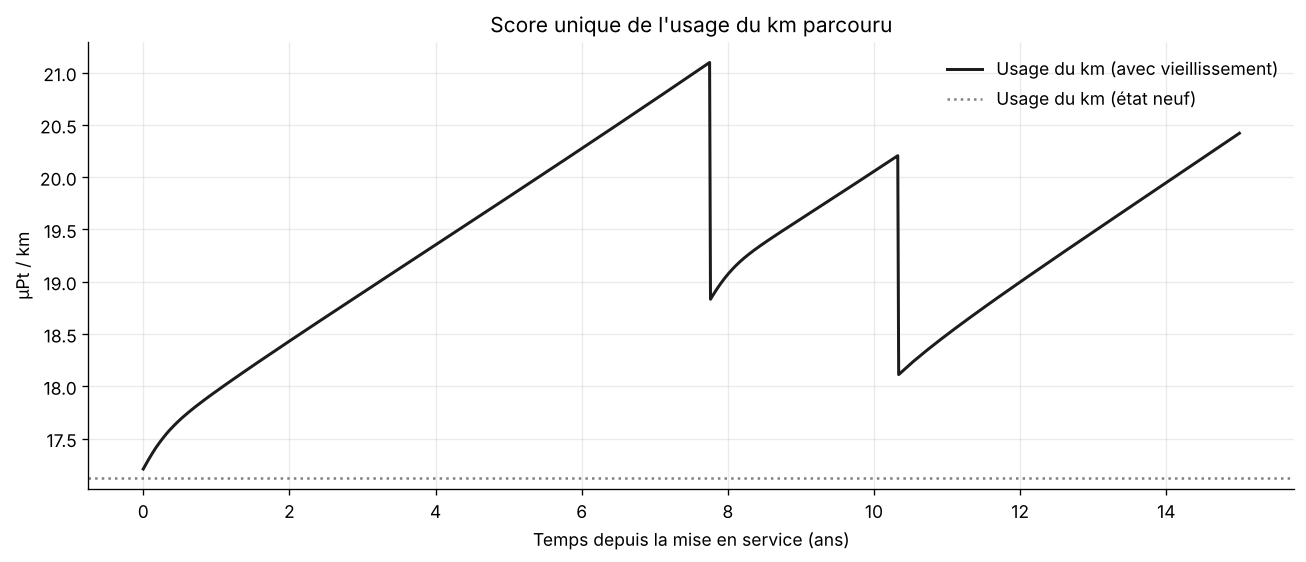

Usage : 17.119 µPt/km à l'état neuf ; maximum 21.097 ; moyenne sur 15 ans 19.346 µPt/km


In [16]:
t=VA["t"];mt=VA["m"]+VA["mp"];ik=ikg_vec(VA["sec"])
su_t=np.array([UPT*score(pd.Series(mt[i]*ik[i],index=IND)) for i in range(len(t))])
su0=UPT*score(pd.Series(M0*ikg_vec([WE_SEC0])[0],index=IND))
fig,ax=plt.subplots(figsize=(11,4.8));ax.plot(t,su_t,color="#1C1C1C",lw=1.8,label="Usage du km (avec vieillissement)")
ax.axhline(su0,color="grey",ls=":",label="Usage du km (état neuf)");ax.set(xlabel="Temps depuis la mise en service (ans)",ylabel="µPt / km",title="Score unique de l'usage du km parcouru")
ax.legend(frameon=False);fig.tight_layout();fig.savefig(OUT/"NW_06_trajectoire_usage.png",dpi=220);plt.show()
print(f"Usage : {su0:.3f} µPt/km à l'état neuf ; maximum {su_t.max():.3f} ; moyenne sur 15 ans {trapz(su_t,t)/t[-1]:.3f} µPt/km")


## 7. Résultat 1 en score unique : phase d'usage sur la vie d'une pile

Même calcul que le notebook de couplage (horizon = vie de la pile, phase d'usage seule, sans perméation du réservoir), exprimé en score unique et comparé au changement climatique.

In [17]:
Tf=pile_tab(FC_CENTRAL)[0];Lp=Tf/HFC_AN
Pp,Vp=detail(L=Lp,res=(0.,0.));   # résultat 1 : phase d'usage seule, sans perméation (comme le notebook de couplage)
use_p=Pp["Électricité"]+Pp["Eau"]+Pp["Compression"];use_0=M0*ikg_vec([WE_SEC0])[0];use_0=pd.Series(use_0,index=IND)
r1=pd.DataFrame({"Neuf":{"Score unique (µPt/km)":UPT*score(use_0),"Climat (g CO2/km)":1000*use_0[GWP]},
 "Moyenne sur la vie de la pile":{"Score unique (µPt/km)":UPT*score(use_p),"Climat (g CO2/km)":1000*use_p[GWP]}}).T
r1.loc["Hausse (%)"]=100*(r1.iloc[1]/r1.iloc[0]-1);display(r1.round(3))
r1cat=pd.DataFrame({"Hausse (%)":100*(normaliser(use_p)/normaliser(use_0)-1)}).sort_values("Hausse (%)");display(r1cat.round(2))


,Score unique (µPt/km),Climat (g CO2/km)
Neuf,17.119,43.422
Moyenne sur la vie de la pile,19.225,48.762
Hausse (%),12.301,12.298


,Hausse (%)
Écotoxicité eau douce,11.98
Couche d'ozone,12.23
Toxicité humaine cancérigène,12.26
Ressources minérales,12.27
Eutrophisation eau douce,12.28
Acidification,12.29
Toxicité humaine non cancérigène,12.29
Particules fines,12.30
Eutrophisation terrestre,12.30
Formation photochimique d'ozone,12.30


## 8. Scénarios de vieillissement (pile × électrolyseur)

,Pile,Électrolyseur,Stacks pile,Score unique (µPt/km),dont usage,dont fabrication,Hausse vs sans vieillissement (%),Climat (g/km)
0,Optimiste,Optimiste,1.0,25.571,19.210,6.361,8.693,79.559
1,Optimiste,Moyen,1.0,25.740,19.379,6.361,9.413,79.988
2,Optimiste,Pessimiste,1.0,25.772,19.369,6.403,9.546,80.303
3,Moyen,Optimiste,2.0,30.825,19.195,11.630,31.026,98.012
4,Moyen,Moyen,2.0,30.975,19.346,11.630,31.666,98.394
5,Moyen,Pessimiste,2.0,31.013,19.342,11.671,31.824,98.724
6,Pessimiste,Optimiste,2.0,31.074,19.443,11.631,32.084,98.650
7,Pessimiste,Moyen,2.0,31.258,19.627,11.631,32.868,99.117
8,Pessimiste,Pessimiste,2.0,31.276,19.603,11.673,32.942,99.400


Électrolyseur,Optimiste,Moyen,Pessimiste
Pile,,,
Optimiste,25.571,25.740,25.772
Moyen,30.825,30.975,31.013
Pessimiste,31.074,31.258,31.276


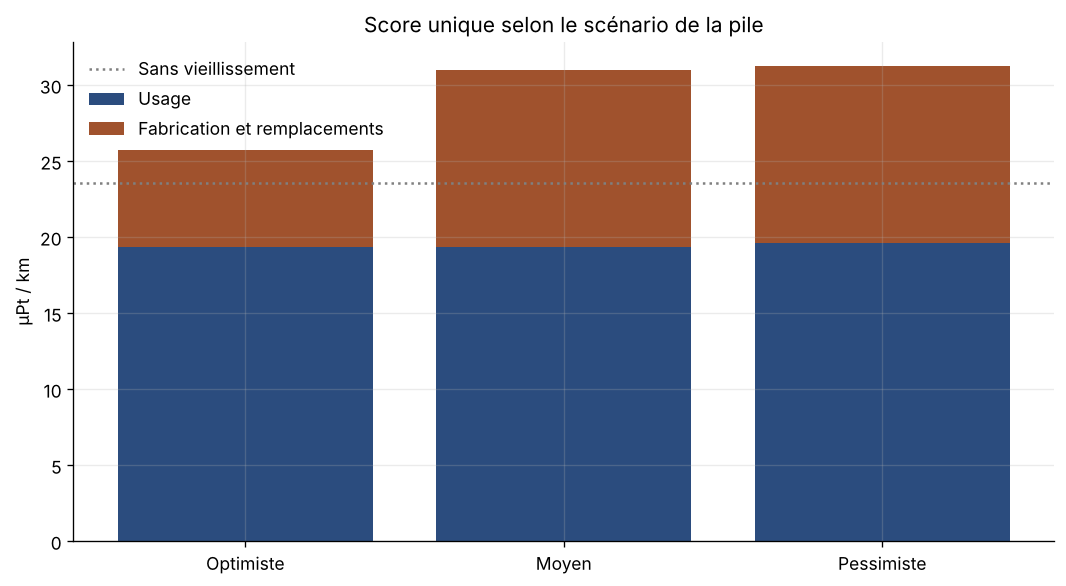

In [18]:
rows=[]
for nf,pf in FC_SCEN.items():
 for nw,pw in WE_SCEN.items():
  P,v=detail(pf,pw);T=sum(P.values())
  rows.append({"Pile":nf,"Électrolyseur":nw,"Stacks pile":v["n_FC"],"Score unique (µPt/km)":UPT*score(T),"dont usage":UPT*score(P["Électricité"]+P["Eau"]+P["Compression"]),
   "dont fabrication":UPT*score(P["Stacks de pile"]+P["Réservoir"]+P["Stacks d'électrolyseur"]),"Hausse vs sans vieillissement (%)":100*(score(T)/score(TR)-1),"Climat (g/km)":1000*T[GWP]})
scen=pd.DataFrame(rows);display(scen.round(3))
mat=scen.pivot(index="Pile",columns="Électrolyseur",values="Score unique (µPt/km)").loc[list(FC_SCEN),list(WE_SCEN)];display(mat.round(3))
fig,ax=plt.subplots(figsize=(9,5));q=scen[scen["Électrolyseur"]=="Moyen"].set_index("Pile").loc[list(FC_SCEN)]
ax.bar(q.index,q["dont usage"],color="#2B4C7E",label="Usage");ax.bar(q.index,q["dont fabrication"],bottom=q["dont usage"],color="#A0522D",label="Fabrication et remplacements")
ax.axhline(SU_R,color="grey",ls=":",label="Sans vieillissement");ax.set(ylabel="µPt / km",title="Score unique selon le scénario de la pile");ax.legend(frameon=False)
fig.tight_layout();fig.savefig(OUT/"NW_07_scenarios.png",dpi=220);plt.show()


## 9. Sensibilité du score unique

Une hypothèse à la fois ; écart au score unique central. Inclut le choix de pondération (renormalisée, poids égaux).

,Hypothèse,Valeur,Score (µPt/km),Écart (%),Hausse due au vieillissement (%)
0,Vie du véhicule,10 ans,28.88,-6.76,8.23
1,Vie du véhicule,20 ans,28.92,-6.63,27.39
2,Stacks de pile et d'électrolyseur,répartition continue,28.08,-9.35,19.36
3,Contenu carbone de l'électricité,× 0.8,27.29,-11.90,34.72
4,Contenu carbone de l'électricité,× 1.2,34.66,11.90,29.36
5,Compression,2 kWh/kg,30.72,-0.83,31.94
6,Compression,5 kWh/kg,31.68,2.29,30.95
7,Réservoir,Optimiste,30.91,-0.21,31.39
8,Réservoir,Pessimiste,31.23,0.83,32.76
9,Échelle électrolyseur,s = 1.0,30.98,0.00,31.67


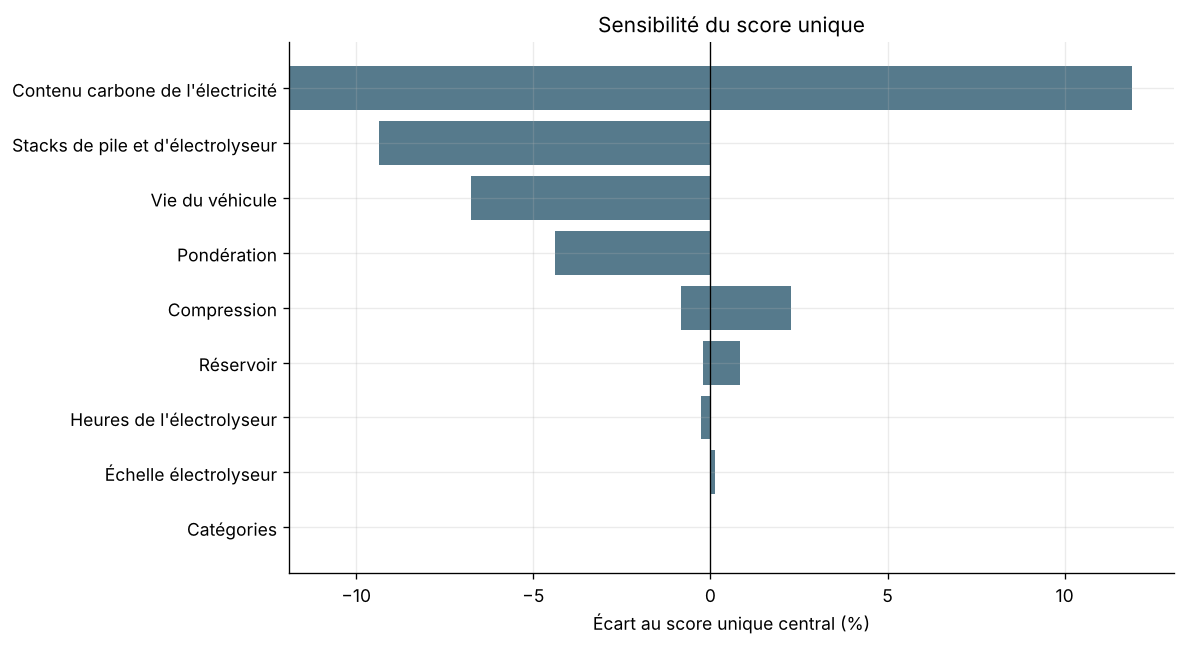

In [19]:
rows=[]
def addS(h,val,**kw):
 P,v=detail(**kw);T=sum(P.values());Pr=detail_ref(**kw);Tr=sum(Pr.values())
 rows.append({"Hypothèse":h,"Valeur":val,"Score (µPt/km)":UPT*score(T),"Écart (%)":100*(score(T)/score(TA)-1),"Hausse due au vieillissement (%)":100*(score(T)/score(Tr)-1)})
for L in [10.,20.]:addS("Vie du véhicule",f"{L:.0f} ans",L=L)
addS("Stacks de pile et d'électrolyseur","répartition continue",discret=False)
for cf in [.8,1.2]:addS("Contenu carbone de l'électricité",f"× {cf}",cf=cf)
for c in [2.,5.]:addS("Compression",f"{c:.0f} kWh/kg",comp=c)
for sc in ["Optimiste","Pessimiste"]:addS("Réservoir",sc,res=sc)
for s in [1.,1.5]:addS("Échelle électrolyseur",f"s = {s}",s_we=s)
for h in [4000.,8000.]:addS("Heures de l'électrolyseur",f"{h:.0f} h/an",hwe=h)
for mode,lab in [("renormalise","poids renormalisés à 100 %"),("egal","poids égaux")]:
 rows.append({"Hypothèse":"Pondération","Valeur":lab,"Score (µPt/km)":UPT*score(TA,mode),"Écart (%)":100*(score(TA,mode)/score(TA)-1),"Hausse due au vieillissement (%)":100*(score(TA,mode)/score(TR,mode)-1)})
def score_fab16(P):   # usage sur 12 catégories + fabrication sur 16 catégories (biais : usage incomplet)
 u=score(P["Électricité"]+P["Eau"]+P["Compression"])
 f=score16(fab16_part(P["Stacks de pile"],F_STACK_FC,FAB16["Stack de pile (128 kW)"]))+score16(fab16_part(P["Réservoir"],F_RES,FAB16["Réservoir"]))+score16(fab16_part(P["Stacks d'électrolyseur"],F_STACK_WE,FAB16["Stack d'électrolyseur (1 MW)"]))
 return u+f
rows.append({"Hypothèse":"Catégories","Valeur":"fabrication sur 16 catégories (usage sur 12)","Score (µPt/km)":UPT*score_fab16(PA),"Écart (%)":100*(score_fab16(PA)/score(TA)-1),"Hausse due au vieillissement (%)":100*(score_fab16(PA)/score_fab16(PR)-1)})
sens=pd.DataFrame(rows);display(sens.round(2))
g=sens.groupby("Hypothèse")["Écart (%)"].agg(["min","max"]);g["min"]=g["min"].clip(upper=0);g["max"]=g["max"].clip(lower=0);g=g.assign(a=g["max"]-g["min"]).sort_values("a")
fig,ax=plt.subplots(figsize=(10,5.5));ax.barh(g.index,g["max"]-g["min"],left=g["min"],color="#567A8C");ax.axvline(0,color="black",lw=.8)
ax.set(xlabel="Écart au score unique central (%)",title="Sensibilité du score unique");fig.tight_layout();fig.savefig(OUT/"NW_08_tornado.png",dpi=220);plt.show()


## 10. Monte-Carlo du score unique

Mêmes tirages que `AB_vieillissement_fabrication` (graine 47, 300 tirages).

,Analyse,Sortie,P5,Médiane,P95
0,Score unique,Score_uPt_km,27.434,32.124,36.092
1,Score unique,Part_fabrication_pct,29.020,38.033,45.874
2,Score unique,Hausse_vieillissement_pct,9.852,31.357,46.408
3,Score unique,Climat_g_km,89.353,106.042,120.017


,Entrée,Rho score,Rho hausse
2,fc_k_R,0.517,0.573
9,CF_electricite,0.489,-0.198
11,Vie_vehicule_ans,-0.237,-0.152
3,fc_k_mem,0.146,0.192
10,P15_reservoir,0.084,0.119
6,we_t50,0.069,0.059
7,Heures_WE_an,0.064,0.107
5,we_fA_min,0.043,-0.013
8,Compression,0.034,-0.014
4,we_k_R,-0.033,-0.075


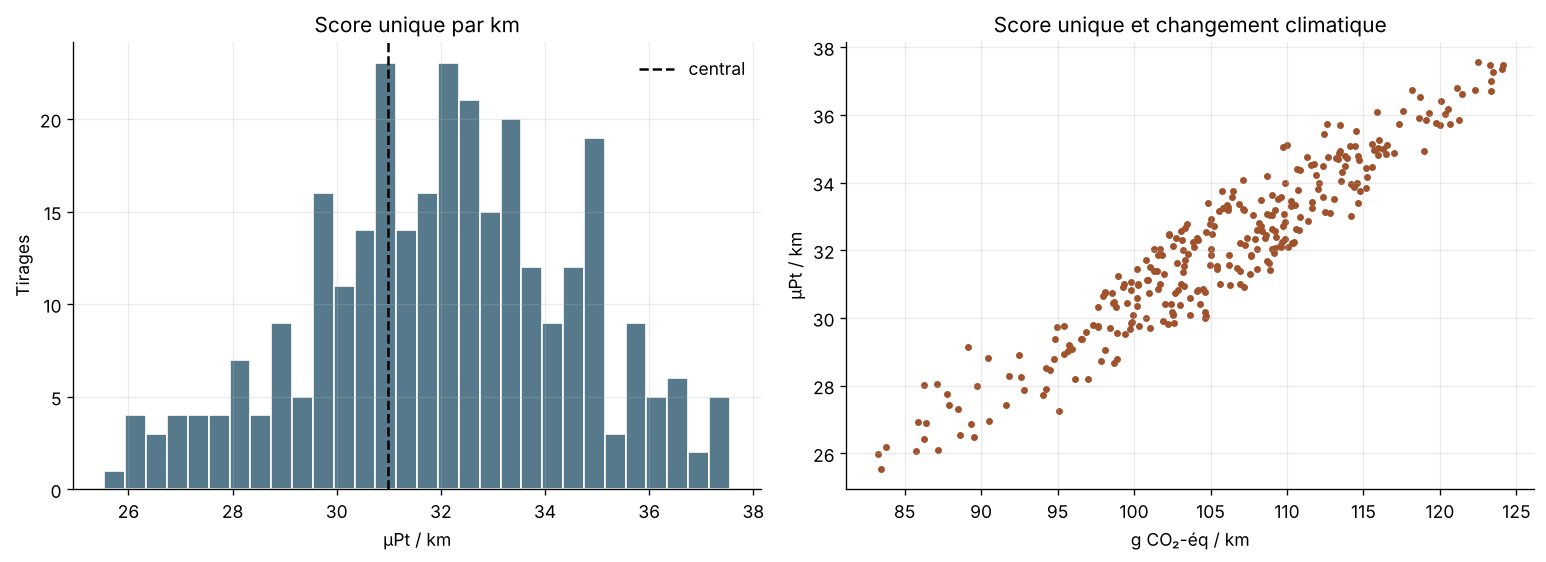

Corrélation de Spearman score unique / climat : 0.933


In [20]:
rng=np.random.default_rng(47);NMC=300
cin=pd.DataFrame({"fc_omega":rng.uniform(*FC_BOUNDS["omega"],NMC),"fc_S1000":rng.uniform(*FC_BOUNDS["S1000"],NMC),
"fc_k_R":rng.uniform(*FC_BOUNDS["k_R"],NMC),"fc_k_mem":rng.uniform(*FC_BOUNDS["k_mem"],NMC),
"we_k_R":rng.uniform(PADGETT["dHFR"],PADGETT["dHFR"]+PADGETT["dCLR"],NMC)/WE_R0,
"we_fA_min":rng.uniform(PADGETT["fA_masse"],PADGETT["fA_capa"],NMC),
"we_t50":rng.uniform(CHANDESRIS_T50["couple"],CHANDESRIS_T50["lineaire"],NMC),
"Heures_WE_an":rng.triangular(4000,6000,8000,NMC),"Compression":rng.triangular(2,3,5,NMC),"CF_electricite":rng.triangular(.8,1,1.2,NMC),
"P15_reservoir":rng.uniform(6,46,NMC),"Vie_vehicule_ans":rng.uniform(10,20,NMC)})
out=[]
for _,r0 in cin.iterrows():
 pf=FC_CENTRAL.copy();pw=WE_CENTRAL.copy()
 pf.update({"omega":r0.fc_omega,"S1000":r0.fc_S1000,"k_R":r0.fc_k_R,"k_mem":r0.fc_k_mem});pw.update({"k_R":r0.we_k_R,"fA_min":r0.we_fA_min,"t50_mem":r0.we_t50})
 P,v=detail(pf,pw,cf=r0.CF_electricite,comp=r0.Compression,res=(6.,r0.P15_reservoir),hwe=r0.Heures_WE_an,L=r0.Vie_vehicule_ans,npa=40);T=sum(P.values())
 Tr=sum(detail_ref(cf=r0.CF_electricite,comp=r0.Compression,res="Optimiste",hwe=r0.Heures_WE_an,L=r0.Vie_vehicule_ans).values())
 out.append({"Score_uPt_km":UPT*score(T),"Part_fabrication_pct":100*score(P["Stacks de pile"]+P["Réservoir"]+P["Stacks d'électrolyseur"])/score(T),
             "Hausse_vieillissement_pct":100*(score(T)/score(Tr)-1),"Climat_g_km":1000*T[GWP]})
mc=pd.concat([cin,pd.DataFrame(out)],axis=1)
mc_sum=percentiles(mc,["Score_uPt_km","Part_fabrication_pct","Hausse_vieillissement_pct","Climat_g_km"],"Score unique");display(mc_sum.round(3))
rho=pd.DataFrame([{"Entrée":x,"Rho score":spearmanr(mc[x],mc.Score_uPt_km).statistic,"Rho hausse":spearmanr(mc[x],mc.Hausse_vieillissement_pct).statistic} for x in cin]).sort_values("Rho score",key=abs,ascending=False)
display(rho.round(3))
fig,axs=plt.subplots(1,2,figsize=(13,4.8));axs[0].hist(mc.Score_uPt_km,bins=30,color="#567A8C",edgecolor="white");axs[0].axvline(SU_A,color="black",ls="--",label="central")
axs[0].set(xlabel="µPt / km",ylabel="Tirages",title="Score unique par km");axs[0].legend(frameon=False)
axs[1].scatter(mc.Climat_g_km,mc.Score_uPt_km,s=10,color="#A0522D");axs[1].set(xlabel="g CO₂-éq / km",ylabel="µPt / km",title="Score unique et changement climatique")
fig.tight_layout();fig.savefig(OUT/"NW_09_MonteCarlo.png",dpi=220);plt.show()
print(f"Corrélation de Spearman score unique / climat : {spearmanr(mc.Climat_g_km,mc.Score_uPt_km).statistic:.3f}")


## 11. Contrôles et export

Toutes les tables sont écrites dans un classeur Excel (une feuille par table) pour le rapport.

In [21]:
checks={"Somme des postes = total (avec)":bool(np.allclose(sum(PA.values()),VA["total"])),
"Total identique au notebook fabrication (98,39 g/km, 200 000 km)":abs(1000*TA[GWP]-98.394)<.1,
"Poids couverts = 100 %":abs(WF_PRESENT-100.)<1e-6,
"Fabrication 16 cat. cohérente avec 12 cat. (climat identique)":bool(np.allclose(FAB16.loc["Changement climatique"].to_numpy(),[v[GWP] for v in FAB_U.values()])),
"Résultat 1 proche du notebook de couplage (48,81 g/km, 200 000 km ; écart < 0,2 %, pas d'intégration différents)":abs(r1.iloc[1]["Climat (g CO2/km)"]-48.812)<.1,
"Score renormalisé = score (16 catégories)":np.isclose(score(TA,"renormalise"),score(TA)/(WF_PRESENT/100)),
"Score positif et fini":bool(np.isfinite(mc.Score_uPt_km).all() and (mc.Score_uPt_km>0).all())}
display(pd.DataFrame({"Contrôle":checks.keys(),"OK":checks.values()}));assert all(checks.values())
with pd.ExcelWriter(OUT/"NW_resultats_normalisation_ponderation.xlsx") as w:
 EF16.to_excel(w,sheet_name="Facteurs EF31");fab_tab.to_excel(w,sheet_name="Fabrication unite");FAB16.to_excel(w,sheet_name="Fabrication caracterisee 16");fab_norm.to_excel(w,sheet_name="Fabrication normalisee");fab_pond.to_excel(w,sheet_name="Fabrication ponderee")
 kg.to_excel(w,sheet_name="kg H2 livre");car.to_excel(w,sheet_name="Caracterise par km");nor.to_excel(w,sheet_name="Normalise par km");pon.to_excel(w,sheet_name="Pondere par km")
 post.to_excel(w,sheet_name="Score par poste");part_pc.to_excel(w,sheet_name="Matrice postes x cat");dec_v.to_excel(w,sheet_name="Effet vieillissement")
 r1.to_excel(w,sheet_name="Resultat 1 usage");scen.to_excel(w,sheet_name="Scenarios",index=False);sens.to_excel(w,sheet_name="Sensibilite",index=False)
 mc_sum.to_excel(w,sheet_name="Monte-Carlo",index=False);rho.to_excel(w,sheet_name="Spearman",index=False)
print("Notebook normalisation validé. Résultats :",OUT.resolve())


,Contrôle,OK
0,Somme des postes = total (avec),True
1,"Total identique au notebook fabrication (98,39 g/km, 200 000 km)",True
2,Poids couverts = 100 %,True
3,Fabrication 16 cat. cohérente avec 12 cat. (climat identique),True
4,"Résultat 1 proche du notebook de couplage (48,81 g/km, 200 000 km ; écart < 0,2 %, pas d'intégration différents)",True
5,Score renormalisé = score (16 catégories),True
6,Score positif et fini,True


Notebook normalisation validé. Résultats : ./resultats_normalisation


## 12. Limites

| Limite | Effet | Traitement |
|---|---|---|
| Usage évalué sur 12 catégories seulement (19,6 % des poids manquent) | score par km sur 12 catégories communes ; les radiations ionisantes (électricité nucléaire) et l'usage des terres de l'électricité ne sont pas comptés | fabrication sur 16 catégories en sensibilité ; à compléter par un export des 4 catégories pour l'électricité, l'eau et la compression |
| Pondération JRC : choix de valeur | le score unique dépend des poids | résultats caractérisés donnés ; poids égaux testés |
| Normalisation mondiale par personne | référence globale, pas européenne | même référence pour tous les postes : la comparaison reste valable |
| Toxicité humaine non cancérigène disponible pour la fabrication seulement | sous-estime la toxicité de l'usage | même traitement que ci-dessus |
| Mêmes limites que `AB_vieillissement_fabrication` (périmètre stacks + réservoir, perméation, vie du véhicule) | voir ce notebook | — |
